# Jaringan Saraf Tiruan LSTM dengan Bayesian Optimization
## Model Dua Tahap (*Two-Stage Hurdle Model*) untuk Prediksi Curah Hujan Ekstrem
### Optimasi Berbasis *Tree-structured Parzen Estimator (TPE)* Multivariat & *Hyperband Successive Halving*

**Afiliasi Akademik:** Universitas Putra Bangsa  
**Lokasi Studi:** Stasiun Klimatologi Jerukagung, Klirong, Kebumen, Jawa Tengah (-7.7667° LS, 109.6167° BT)  
**Kerangka Model:** Two-Stage Hurdle Model (Tahap 1: Klasifikasi Kejadian Hujan; Tahap 2: Regresi Intensitas Presipitasi) berbasis Stacked LSTM dengan Bayesian HPO

## 1. Landasan Teori & Metodologi Penelitian: Model Dua Tahap (*Two-Stage Hurdle*) & *Bayesian Optimization*

Penelitian ini memfokuskan pada arsitektur **Model Dua Tahap (*Two-Stage Hurdle Model*)** berbasis *Deep Learning* LSTM yang dioptimalkan menggunakan **Bayesian Optimization (TPE Multivariat + Hyperband)** untuk peramalan curah hujan ekstrem jangka pendek (*short-term extreme rainfall forecasting*).

---

### A. Tantangan *Zero-Inflation* & Arsitektur Dua Tahap (*Two-Stage Hurdle*)
Data curah hujan di wilayah tropis seperti Kebumen memiliki karakteristik *zero-inflated* yang sangat ekstrem (>85% jam kering/tanpa presipitasi). 
Regresi tunggal konvensional langsung pada target curah hujan akan mengalami kegagalan sistemik:
1. Model memprediksi gerimis artifisial (*artificial drizzle*) secara terus-menerus pada setiap jam untuk meminimalkan *Mean Squared Error*.
2. Nilai ekor ekstrem (*heavy-tailed extreme events*) gagal dipelajari karena teredam oleh dominasi masif nilai nol.

**Solusi Two-Stage Hurdle:**
- **Tahap 1 (Occurrence Classifier)**: Memprediksi *apakah hujan terjadi atau tidak* ($P(\text{rain} \ge 0.2\text{ mm/jam})$) dengan optimasi metrik **F1-Score** dan pencarian ambang batas probabilitas dinamis ($\tau \in [0.20, 0.70]$).
- **Tahap 2 (Intensity Regressor)**: Memprediksi *seberapa lebat curah hujan* dalam satuan log-transformasi $\log(1 + y)$ **hanya pada sampel dengan kejadian presipitasi positif**.
- **Joint Hurdle Inference**: Intensitas hanya dikeluarkan jika model Tahap 1 mengonfirmasi terjadinya hujan:
  $$\hat{y} = \begin{cases} \exp(\hat{y}_{\text{reg}}) - 1 & \text{jika } \hat{y}_{\text{occ}} = 1 \\ 0 & \text{jika } \hat{y}_{\text{occ}} = 0 \end{cases}$$

---

### B. Mekanisme *Tree-structured Parzen Estimator (TPE)* Multivariat
Algoritma **Tree-structured Parzen Estimator (TPE)** memodelkan fungsi objektif tersembunyi dengan memodelkan densitas bersyarat $p(x|y)$ menggunakan *Non-parametric Kernel Density Estimators*:

$$p(x|y) = \begin{cases} \ell(x) & \text{jika } y < y^* \\ g(x) & \text{jika } y \ge y^* \end{cases}$$

Di mana $y^*$ adalah ambang kuantil $\gamma = 0.20$ (20% konfigurasi model terbaik). TPE memaksimalkan rasio kriteria **Expected Improvement (EI)**:

$$\text{EI}_{y^*}(x) \propto \left( \gamma + \frac{g(x)}{\ell(x)} (1-\gamma) \right)^{-1}$$

Dengan opsi **`multivariate=True`**, estimasi kernel menangkap interaksi multidimensi antar parameter LSTM (*learning rate* vs *batch size*, *units* vs *dropout/weight decay*).

---

### C. Efisiensi Komputasi: *Hyperband Successive Halving*
`HyperbandPruner` mengalokasikan sumber daya secara bertingkat:
- Rung awal pada epoch 5 (`min_resource = 5`).
- Mengeliminasi $2/3$ trial terbawah (`reduction_factor = 3`) pada setiap rung.
- Hanya melatih $1/3$ model paling menjanjikan hingga epoch 30 (`max_resource = 30`), menghemat hingga 70% waktu komputasi GPU.

## Tahap 1: Inisialisasi dan Impor Library

Sel ini memuat semua pustaka (library) yang dibutuhkan oleh model, termasuk manipulasi data (Pandas/Numpy), pemodelan (XGBoost/Tensorflow), metrik evaluasi (Scikit-Learn), serta mematikan peringatan (*warnings*) agar *output* tetap bersih.

In [1]:
# Sel 1: Impor Library dan Setup Lingkungan
import os
import sys
import json
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import optuna
import shap
import scipy.stats as stats

from pathlib import Path
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression  # Untuk Platt Scaling [AUDIT FIX]
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, auc, confusion_matrix,
    brier_score_loss, mean_squared_error, mean_absolute_error, r2_score
)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['lines.linewidth'] = 2.0

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger()
logger.info("Kerangka Pemodelan Prediksi Curah Hujan 1-Jam Dimulai...")


from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.base import BaseEstimator, ClassifierMixin
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, CSVLogger, ModelCheckpoint

# Fungsi utilitas untuk mengecek proporsi dataset secara terpisah
def print_dataset_distribution(title, X_tr, y_tr, X_va, y_va, X_te, y_te):
    n_train = len(X_tr)
    n_val = len(X_va)
    n_test = len(X_te)
    total = n_train + n_val + n_test
    
    y_tr_np = np.array(y_tr)
    y_va_np = np.array(y_va)
    y_te_np = np.array(y_te)
    
    rain = int(np.sum(y_tr_np == 1) + np.sum(y_va_np == 1) + np.sum(y_te_np == 1))
    non_rain = int(np.sum(y_tr_np == 0) + np.sum(y_va_np == 0) + np.sum(y_te_np == 0))
    
    rain_pct = (rain / total) * 100 if total > 0 else 0
    non_rain_pct = (non_rain / total) * 100 if total > 0 else 0
    pos_neg_ratio = rain / (non_rain + 1e-9)
    
    print("==============================")
    print(f"Dataset Distribution ({title})")
    print("==============================")
    print(f"Training samples: {n_train}")
    print(f"Validation samples: {n_val}")
    print(f"Testing samples: {n_test}")
    print(f"Rain samples: {rain}")
    print(f"Non-rain samples: {non_rain}")
    print(f"Rain percentage: {rain_pct:.2f}%")
    print(f"Non-rain percentage: {non_rain_pct:.2f}%")
    print(f"Positive/Negative ratio: {pos_neg_ratio:.4f}")
    print("=" * 30)

def cek_proporsi_pretraining(X_tr, y_tr, X_va, y_va, X_te, y_te):
    print_dataset_distribution("Pretraining", X_tr, y_tr, X_va, y_va, X_te, y_te)

def cek_proporsi_finetuning(X_tr, y_tr, X_va, y_va, X_te, y_te):
    print_dataset_distribution("Fine-Tuning", X_tr, y_tr, X_va, y_va, X_te, y_te)


2026-10-30 02:45:43,957 - INFO - Kerangka Pemodelan Prediksi Curah Hujan 1-Jam Dimulai...


## Tahap 2: Konfigurasi Global & Konstanta

Sel ini mendefinisikan seluruh variabel kontrol untuk *pipeline*. Anda bisa mengganti mode berjalannya notebook (`RUN_MODE`) menjadi mode cepat (*fast-test*) atau mode penuh (*pipeline_test*), serta menentukan jumlah *trials* Optuna.

In [2]:
# Sel 2: Konfigurasi Global
# File ini mendefinisikan konstanta fisik, rentang waktu pemodelan, dan parameter Bayesian HPO.
RUN_MODE = "FULL_TRAIN"  # "FULL_TRAIN" untuk latihan penuh, "PIPELINE_TEST" untuk uji coba cepat
SEED = 281225

if RUN_MODE == "PIPELINE_TEST":
    OPTUNA_TRIALS    = 5
    EPOCHS_HPO       = 2   # Epoch per trial Optuna (singkat agar eksplorasi cepat)
    EPOCHS_BEST      = 2   # Epoch training model terbaik (biarkan EarlyStopping bekerja)
else:
    OPTUNA_TRIALS    = 50  # Jumlah trial optimasi Bayesian dengan Optuna
    EPOCHS_HPO       = 30  # Epoch per trial Optuna — alokasi maksimum Hyperband
    EPOCHS_BEST      = 60  # Epoch training model terbaik pasca-HPO (konvergensi penuh)

# Panjang urutan waktu (sequence lookback) ke belakang untuk LSTM (24 jam = 1 siklus diurnal)
LOOKBACK = 24

# Direktori output model, database HPO, dan visualisasi
from pathlib import Path
BASE_OUTPUT_DIR = Path('outputs_lstm_bayesian')

# Batas ambang curah hujan untuk klasifikasi hujan/tidak hujan (mm/jam)
RAIN_THRESHOLD = 0.2

# ==============================================================================
# Konfigurasi Bayesian Optimization (Optuna Multivariate TPE + Hyperband)
# ==============================================================================
BAYESIAN_N_STARTUP_TRIALS = 15   # Eksplorasi acak awal untuk estimasi kernel Parzen
BAYESIAN_GAMMA             = 0.20  # Kuantil pemisah kelompok top 20% ell(x) vs g(x)
HYPERBAND_MIN_RESOURCE     = 5     # Rung pertama evaluasi pruning (epoch 5)
HYPERBAND_MAX_RESOURCE     = 30    # Alokasi sumber daya maksimum per trial (epoch 30)
HYPERBAND_REDUCTION_FACTOR = 3     # Faktor eliminasi 1/3 yang lolos ke rung berikutnya

# Ruang pencarian hiperparameter (Search Space) yang diperluas
SEARCH_UNITS_L1          = [64, 128]        # Asli model-ltsm-final (ringan & cepat)
SEARCH_UNITS_L2          = [32, 64]         # Asli model-ltsm-final
SEARCH_DROPOUT           = [0.1, 0.2, 0.3]  # Asli model-ltsm-final
SEARCH_BATCH             = [64, 128, 256]   # Asli model-ltsm-final
SEARCH_LR_MIN            = 1e-4             # Asli model-ltsm-final
SEARCH_LR_MAX            = 5e-3             # Asli model-ltsm-final

# Rentang tanggal pre-training menggunakan data satelit & ERA5 (2005 - 2025)
# Selaras 100% dengan model-ltsm-final.py dan model-ltsm-final.ipynb
PRETRAIN__TRAIN_START = '2005-01-01'
PRETRAIN__TRAIN_END   = '2020-12-31'
PRETRAIN__VAL_START   = '2021-01-01'
PRETRAIN__VAL_END     = '2023-12-31'
PRETRAIN__TEST_START  = '2024-01-01'
PRETRAIN__TEST_END    = '2025-12-31'

# Backward compatibility alias (kompatibel penuh dengan kode lama)
TRAIN_START = PRETRAIN__TRAIN_START
TRAIN_END   = PRETRAIN__TRAIN_END
VAL_START   = PRETRAIN__VAL_START
VAL_END     = PRETRAIN__VAL_END
TEST_START  = PRETRAIN__TEST_START
TEST_END    = PRETRAIN__TEST_END

# Pemetaan fitur dari kolom mentah dataset ERA5 ke nama variabel meteorologi standar
ERA5_FEATURES_MAPPING = {
    'temperature_era5': 'temperature',
    'humidity_era5': 'humidity',
    'dewpoint_era5': 'dewpoint',
    'rain_mm': 'rainrate',
    'sealevel_pressure_era5': 'pressure',
    'u10_era5': 'era5_u_wind',
    'v10_era5': 'era5_v_wind',
    'cloud_cover_era5': 'era5_cloud_cover',
    'cape_era5': 'era5_cape',
    'total_column_water_vapour_era5': 'era5_tcwv',
    'moisture_divergence_era5': 'era5_moisture_div',
    'direct_radiation_era5': 'era5_direct_rad',
    'sunshine_duration_era5': 'era5_sunshine'
}

## Tahap 3: Mesin Evaluasi Terpadu (*ModelEvaluator*)

Ini adalah mesin (*engine*) utama untuk melakukan pelaporan hasil model. Kelas ini bertanggung jawab menghitung semua metrik meteorologi (CSI, POD, FAR), metrik klasifikasi (ROC-AUC), metrik regresi (RMSE), serta menyimpan seluruh grafik evaluasi dan kurva kalibrasi secara otomatis ke folder `outputs_lstm/`.

In [3]:
# Sel 3: Mesin Evaluasi Terpadu (Unified Evaluation Engine)
def fit_best_calibrator(y_val, val_probs):
    from sklearn.linear_model import LogisticRegression
    from sklearn.isotonic import IsotonicRegression
    from sklearn.metrics import brier_score_loss
    
    # Platt
    platt = LogisticRegression()
    try:
        platt.fit(val_probs.reshape(-1, 1), y_val)
        platt_probs = platt.predict_proba(val_probs.reshape(-1, 1))[:, 1]
        platt_brier = brier_score_loss(y_val, platt_probs)
    except:
        platt = None
        platt_brier = 999
        
    # Isotonic
    iso = IsotonicRegression(out_of_bounds='clip')
    try:
        iso.fit(val_probs, y_val)
        iso_probs = iso.predict(val_probs)
        iso_brier = brier_score_loss(y_val, iso_probs)
    except:
        iso = None
        iso_brier = 999
        
    raw_brier = brier_score_loss(y_val, val_probs)
    
    logger.info(f"[Calibrator Selection] Brier scores - Raw: {raw_brier:.4f}, Platt: {platt_brier:.4f}, Isotonic: {iso_brier:.4f}")
    
    if iso_brier <= platt_brier and iso_brier < raw_brier:
        logger.info("[Calibrator Selection] Selected Isotonic Calibrator")
        return iso, "Isotonic"
    elif platt_brier < iso_brier and platt_brier < raw_brier:
        logger.info("[Calibrator Selection] Selected Platt Calibrator")
        return platt, "Platt"
    else:
        logger.info("[Calibrator Selection] Selected Raw Calibrator (No calibration applied)")
        return None, "Raw"

def apply_calibrator(calibrator, calibrator_type, probs):
    if calibrator_type == "Isotonic":
        return calibrator.predict(probs)
    elif calibrator_type == "Platt":
        return calibrator.predict_proba(probs.reshape(-1, 1))[:, 1]
    else:
        return probs.copy()

def compute_ece_mce(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece, mce = 0.0, 0.0
    n = len(y_true)
    y_true_np = np.array(y_true)
    y_prob_np = np.array(y_prob)
    for i in range(n_bins):
        mask = (y_prob_np >= bins[i]) & (y_prob_np < bins[i+1])
        if mask.sum() == 0:
            continue
        acc  = y_true_np[mask].mean()
        conf = y_prob_np[mask].mean()
        err  = abs(acc - conf)
        ece += (mask.sum() / n) * err
        mce  = max(mce, err)
    return float(ece), float(mce)

class ModelEvaluator:
    def __init__(self, base_dir=None, phase=None):
        self.base_dir = base_dir if base_dir is not None else globals().get('BASE_OUTPUT_DIR')
        self.phase = phase # 'pretraining' or 'finetuning'
        
        if phase:
            self.dirs = {
                'metrics': self.base_dir / self.phase,
                'plots': self.base_dir / self.phase / 'figures',
                'reports': self.base_dir / self.phase,
            }
        else:
            self.dirs = {
                'metrics': self.base_dir / 'metrics',
                'plots': self.base_dir / 'plots',
                'reports': self.base_dir / 'reports',
            }
        
        self.dirs['models'] = self.base_dir / 'models'
        self.dirs['models_clf'] = self.base_dir / 'models' / 'classifier'
        self.dirs['models_reg'] = self.base_dir / 'models' / 'regressor'
        self.dirs['models_cal'] = self.base_dir / 'models' / 'calibration'
        
        for d in self.dirs.values():
            d.mkdir(parents=True, exist_ok=True)
            
        self.clf_metrics = {}
        self.meteo_metrics = {}
        self.reg_metrics = {}
        
    def calc_meteorological_metrics(self, y_true, y_pred):
        hits = np.sum((y_pred == 1) & (y_true == 1))
        misses = np.sum((y_pred == 0) & (y_true == 1))
        false_alarms = np.sum((y_pred == 1) & (y_true == 0))
        correct_negatives = np.sum((y_pred == 0) & (y_true == 0))
        
        total = len(y_true)
        hits_random = ((hits + misses) * (hits + false_alarms)) / (total + 1e-9)
        
        csi = hits / (hits + misses + false_alarms + 1e-9)
        pod = hits / (hits + misses + 1e-9)
        far = false_alarms / (hits + false_alarms + 1e-9)
        ets = (hits - hits_random) / (hits + misses + false_alarms - hits_random + 1e-9)
        hss = 2 * (hits * correct_negatives - misses * false_alarms) / ((hits + misses) * (misses + correct_negatives) + (hits + false_alarms) * (false_alarms + correct_negatives) + 1e-9)
        
        return {'CSI': float(csi), 'POD': float(pod), 'FAR': float(far), 'ETS': float(ets), 'HSS': float(hss)}

    def calc_hydrological_metrics(self, y_true, y_pred):
        if len(y_true) < 2: return {'NSE': 0.0, 'KGE': 0.0, 'Correlation': 0.0}
        mean_obs, mean_sim = np.mean(y_true), np.mean(y_pred)
        std_obs, std_sim = np.std(y_true), np.std(y_pred)
        
        numerator = np.sum((y_true - y_pred)**2)
        denominator = np.sum((y_true - mean_obs)**2)
        nse = 1 - (numerator / (denominator + 1e-9))
        
        if std_obs > 0 and std_sim > 0:
            r = np.corrcoef(y_true, y_pred)[0, 1]
            alpha = std_sim / (std_obs + 1e-9)
            beta = mean_sim / (mean_obs + 1e-9)
            kge = 1 - np.sqrt((r - 1)**2 + (beta - 1)**2 + (alpha - 1)**2)
        else:
            r, kge = 0.0, 0.0
            
        return {'NSE': float(nse), 'KGE': float(kge), 'Correlation': float(r)}

    def evaluate_classification(self, y_true, y_prob_uncal, y_prob_cal, y_pred):
        logger.info("Menghitung metrik klasifikasi...")
        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, zero_division=0)
        rec = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_true, y_prob_cal)
        
        brier_uncal = brier_score_loss(y_true, y_prob_uncal)
        brier_cal = brier_score_loss(y_true, y_prob_cal)
        
        precision_arr, recall_arr, _ = precision_recall_curve(y_true, y_prob_cal)
        pr_auc = auc(recall_arr, precision_arr)
        
        self.clf_metrics = {
            'Accuracy': float(acc), 
            'Precision': float(prec), 
            'Recall': float(rec), 
            'F1 Score': float(f1), 
            'ROC-AUC': float(roc_auc), 
            'PR-AUC': float(pr_auc), 
            'Brier Score (Uncalibrated)': float(brier_uncal),
            'Brier Score (Calibrated)': float(brier_cal)
        }
        
        self.meteo_metrics = self.calc_meteorological_metrics(y_true, y_pred)
        
        self.plot_calibration_curve(y_true, y_prob_uncal, y_prob_cal)
        self.plot_reliability_diagram(y_true, y_prob_uncal, y_prob_cal)
        self.plot_probability_distribution(y_prob_cal)
        self.plot_roc_curve(y_true, y_prob_cal)
        self.plot_precision_recall_curve(y_true, y_prob_cal)
        self.plot_threshold_analysis(y_true, y_prob_cal)
        
        self.save_combined_metrics()
        
        return self.clf_metrics, self.meteo_metrics

    def evaluate_regression(self, y_true, y_pred):
        logger.info("Menghitung metrik regresi...")
        if len(y_true) == 0: return {}
        
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        mae = mean_absolute_error(y_true, y_pred)
        r2 = r2_score(y_true, y_pred)
        bias = np.mean(y_pred - y_true)
        
        hydro = self.calc_hydrological_metrics(y_true, y_pred)
        
        self.reg_metrics = {'RMSE': float(rmse), 'MAE': float(mae), 'R2': float(r2), 'Bias': float(bias)}
        self.reg_metrics.update(hydro)
        
        self.plot_prediction_vs_observation(y_true, y_pred)
        self.plot_error_distribution(y_true, y_pred)
        residuals = y_true - y_pred
        self.plot_residual_distribution(residuals)
        self.plot_qq_plot(residuals)
        self.plot_rainfall_event_comparison(y_true, y_pred)
        
        self.save_combined_metrics()
        
        return self.reg_metrics

    def save_combined_metrics(self):
        combined = {
            'classification': self.clf_metrics,
            'meteorological': self.meteo_metrics,
            'regression': self.reg_metrics
        }
        with open(self.dirs['metrics'] / 'metrics.json', 'w') as f:
            json.dump(combined, f, indent=4)

    def plot_reliability_diagram(self, y_true, y_prob_uncal, y_prob_cal, filename='reliability_diagram.png'):
        plt.figure(figsize=(10,8))
        if y_prob_cal is not None:
            prob_true_c, prob_pred_c = calibration_curve(y_true, y_prob_cal, n_bins=10)
            plt.plot(prob_pred_c, prob_true_c, marker='s', label='Calibrated')
        plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
        plt.title('Reliability Diagram')
        plt.xlabel('Prediksi Probabilitas')
        plt.ylabel('Fraksi Positif Aktual')
        plt.legend()
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_probability_distribution(self, y_prob_cal):
        plt.figure(figsize=(10,6))
        sns.histplot(y_prob_cal, bins=20, kde=True, color='green', alpha=0.5)
        plt.title('Probability Distribution')
        plt.xlabel('Prediksi Probabilitas')
        plt.ylabel('Frekuensi')
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / 'probability_distribution.png', dpi=300)
        plt.show()
        plt.close()

    def plot_calibration_curve(self, y_true, y_prob_uncal, y_prob_cal=None, filename='calibration_curve.png'):
        plt.figure(figsize=(10,8))
        prob_true, prob_pred = calibration_curve(y_true, y_prob_uncal, n_bins=10)
        plt.plot(prob_pred, prob_true, marker='o', label='Uncalibrated Model', color='blue')
        if y_prob_cal is not None:
            prob_true_c, prob_pred_c = calibration_curve(y_true, y_prob_cal, n_bins=10)
            plt.plot(prob_pred_c, prob_true_c, marker='s', label='Calibrated Model', color='green')
        plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
        plt.title('Calibration Curve')
        plt.xlabel('Prediksi Probabilitas')
        plt.ylabel('Fraksi Positif Aktual')
        plt.legend()
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_confusion_matrix(self, y_true, y_pred, filename='20_confusion_matrix_two_stage.png', suffix=''):
        cm = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(8, 6.5))
        sns.heatmap(
            cm, annot=True, fmt=',d', cmap='Purples', cbar=False,
            linewidths=2.0, linecolor='white',
            annot_kws={'size': 16, 'weight': 'bold'}
        )
        plt.title(f'Confusion Matrix {suffix}', fontsize=13, fontweight='bold', pad=12)
        plt.ylabel('Aktual (Ground Truth)', fontsize=11, fontweight='bold')
        plt.xlabel('Prediksi Model', fontsize=11, fontweight='bold')
        plt.xticks([0.5, 1.5], ['Tidak Hujan (0)', 'Hujan (1)'], fontsize=11, fontweight='bold')
        plt.yticks([0.5, 1.5], ['Tidak Hujan (0)', 'Hujan (1)'], fontsize=11, fontweight='bold')
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_roc_curve(self, y_true, y_prob, filename='roc_curve.png'):
        plt.figure(figsize=(10,8))
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC={auc(fpr, tpr):.4f})')
        plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.title('Receiver Operating Characteristic (ROC) Curve')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.legend(loc="lower right")
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_precision_recall_curve(self, y_true, y_prob, filename='precision_recall_curve.png'):
        plt.figure(figsize=(10,8))
        precision, recall, _ = precision_recall_curve(y_true, y_prob)
        plt.plot(recall, precision, color='purple', lw=2, label=f'PR Curve (AUC={auc(recall, precision):.4f})')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.title('Precision-Recall Curve')
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.legend(loc="lower left")
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_threshold_analysis(self, y_true, y_prob, filename='threshold_analysis.png'):
        plt.figure(figsize=(10,6))
        thresholds = np.linspace(0.1, 0.9, 50)
        f1_scores = [f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
        plt.plot(thresholds, f1_scores, marker='x', color='blue')
        plt.title('Threshold Analysis (F1 Score)')
        plt.xlabel('Threshold')
        plt.ylabel('F1 Score')
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_prediction_vs_observation(self, y_true, y_pred, filename='prediction_vs_observation.png'):
        plt.figure(figsize=(10,8))
        plt.scatter(y_true, y_pred, alpha=0.5, color='blue')
        max_val = max(np.max(y_true), np.max(y_pred))
        plt.plot([0, max_val], [0, max_val], color='red', linestyle='--')
        plt.title('Prediction vs Observation')
        plt.xlabel('Observasi (mm/jam)')
        plt.ylabel('Prediksi (mm/jam)')
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_residual_distribution(self, residuals, filename='residual_distribution.png'):
        plt.figure(figsize=(10,6))
        sns.histplot(residuals, kde=True, color='crimson')
        plt.title('Residual Distribution')
        plt.xlabel('Residual (Observasi - Prediksi)')
        plt.ylabel('Kepadatan')
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_qq_plot(self, residuals, filename='qq_plot.png'):
        plt.figure(figsize=(10,8))
        stats.probplot(residuals, dist="norm", plot=plt)
        plt.title('Normal Q-Q Plot')
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_error_distribution(self, y_true, y_pred, filename='error_distribution.png'):
        plt.figure(figsize=(10,6))
        abs_errors = np.abs(y_true - y_pred)
        sns.boxplot(y=abs_errors, color='orange')
        plt.title('Absolute Error Distribution')
        plt.ylabel('Absolute Error (mm/jam)')
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_timeseries_prediction_vs_observation(self, y_true, y_pred, timestamps, filename='timeseries_prediction_vs_observation.png'):
        plt.figure(figsize=(15,6))
        plt.plot(timestamps, y_true, label='Observasi', color='blue', alpha=0.7)
        plt.plot(timestamps, y_pred, label='Prediksi', color='red', alpha=0.7)
        plt.title('Timeseries Prediction vs Observation')
        plt.xlabel('Waktu')
        plt.ylabel('Curah Hujan (mm/jam)')
        plt.legend()
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_rainfall_event_comparison(self, y_true, y_pred, filename='rainfall_event_comparison.png'):
        plt.figure(figsize=(12,6))
        indices = np.arange(len(y_true))
        plt.bar(indices - 0.2, y_true, width=0.4, label='Observasi', color='blue', alpha=0.7)
        plt.bar(indices + 0.2, y_pred, width=0.4, label='Prediksi', color='red', alpha=0.7)
        plt.title('Rainfall Event Intensity Comparison')
        plt.xlabel('Indeks Sampel Hujan')
        plt.ylabel('Intensitas (mm/jam)')
        plt.legend()
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def plot_cumulative_rainfall(self, y_true, y_pred, timestamps, filename='cumulative_rainfall.png'):
        plt.figure(figsize=(15,6))
        plt.plot(timestamps, np.cumsum(y_true), label='Cumulative Observasi', color='blue')
        plt.plot(timestamps, np.cumsum(y_pred), label='Cumulative Prediksi', color='red')
        plt.title('Cumulative Rainfall Over Time')
        plt.xlabel('Waktu')
        plt.ylabel('Akumulasi Curah Hujan (mm)')
        plt.legend()
        plt.tight_layout()
        plt.savefig(self.dirs['plots'] / filename, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    def generate_report(self, n_train, n_val, n_test, feature_names, clf_metrics, meteo_metrics, reg_metrics, algorithm_name):
        thresh = globals().get('RAIN_THRESHOLD', 0.2)
        features_list = "\n".join([f"- {f}" for f in feature_names])
        
        report_content = f"""# Laporan Evaluasi Model Prediksi Curah Hujan Akumulasi 1-Jam
        
## Deskripsi Model
Framework ini membangun arsitektur dua tahap (*Two-Stage Model*) untuk memprediksi curah hujan akumulasi 1-jam.
Tahap pertama mengklasifikasikan kejadian hujan (P(Hujan) >= {thresh} mm), kemudian tahap kedua (regresi) menebak nilai intensitas untuk wilayah yang diklasifikasikan hujan.
**Algoritma Inti:** {algorithm_name}

## Jumlah Data
- **Jumlah Data Latih**: {n_train}
- **Jumlah Data Validasi**: {n_val}
- **Jumlah Data Uji**: {n_test}

## Daftar Variabel
{features_list}

## Hasil Klasifikasi
- Accuracy: {clf_metrics.get('Accuracy', 0):.4f}
- Precision: {clf_metrics.get('Precision', 0):.4f}
- Recall: {clf_metrics.get('Recall', 0):.4f}
- F1 Score: {clf_metrics.get('F1 Score', 0):.4f}
- ROC-AUC: {clf_metrics.get('ROC-AUC', 0):.4f}
- PR-AUC: {clf_metrics.get('PR-AUC', 0):.4f}
- Brier Score (Uncalibrated): {clf_metrics.get('Brier Score (Uncalibrated)', 0):.4f}
- Brier Score (Calibrated): {clf_metrics.get('Brier Score (Calibrated)', 0):.4f}

## Hasil Metrik Meteorologi
- CSI (Critical Success Index): {meteo_metrics.get('CSI', 0):.4f}
- POD (Probability of Detection): {meteo_metrics.get('POD', 0):.4f}
- FAR (False Alarm Ratio): {meteo_metrics.get('FAR', 0):.4f}
- ETS (Equitable Threat Score): {meteo_metrics.get('ETS', 0):.4f}
- HSS (Heidke Skill Score): {meteo_metrics.get('HSS', 0):.4f}

## Hasil Regresi
*(Dihitung eksklusif pada sampel aktual yang mengalami hujan)*
- RMSE (Root Mean Squared Error): {reg_metrics.get('RMSE', 0):.4f} mm
- MAE (Mean Absolute Error): {reg_metrics.get('MAE', 0):.4f} mm
- R² (Koefisien Determinasi): {reg_metrics.get('R2', 0):.4f}
- Bias: {reg_metrics.get('Bias', 0):.4f}
- Correlation: {reg_metrics.get('Correlation', 0):.4f}

## Analisis Feature Importance
*Silakan merujuk ke folder `figures/` untuk melihat visualisasi SHAP dan diagram kepentingan fitur (Feature Importance) terhadap prediksi model.*
"""
        with open(self.dirs['reports'] / 'classification_report.txt', 'w') as f:
            f.write(report_content)


## Pemuatan Data Satelit & Reanalisis ERA5

**Tujuan:** Memuat dan menggabungkan data hidrometeorologi ERA5 reanalisis serta data presipitasi satelit resolusi 1-jam untuk melatih model Two-Stage Hurdle LSTM.

In [4]:
# Sel 4: Pemuatan Data dan Penyatuan (Data Loading & Merge)
# Menggabungkan data historis cuaca ERA5 dengan target curah hujan satelit GSMaP untuk pre-training.
# Sel 4: Pemuatan Data dan Penyatuan (Data Loading & Merge)

import os
from pathlib import Path
import pandas as pd
import numpy as np

logger.info("Loading ERA5 + GSMaP dataset...")

# =============================================================================
# PATH
# =============================================================================
if os.path.exists('/kaggle/input'):
    import glob
    search_file = glob.glob('/kaggle/input/**/ERA5_Hourly_All_Requested_Features_2000_2026.csv', recursive=True)
    if not search_file:
        search_file = glob.glob('/kaggle/input/**/ERA5_Hourly_All_Requested_Features.csv', recursive=True)
    SAT_DIR = Path(search_file[0]).parent if search_file else Path('/kaggle/input/datasets/jerismeteo/google-earth-engine-data')
else:
    _candidates = [
        Path.cwd() / 'Google_Earth_Engine' / 'Data_Satelit',
        Path.cwd().parent / 'Google_Earth_Engine' / 'Data_Satelit',
        Path('D:/Github/Projek_Rainfall') / 'Google_Earth_Engine' / 'Data_Satelit'
    ]
    SAT_DIR = next((p for p in _candidates if p.exists()), Path('D:/Github/Projek_Rainfall') / 'Google_Earth_Engine' / 'Data_Satelit')

# =============================================================================
# LOAD ERA5
# =============================================================================
_era5_cand = [
    SAT_DIR / "ERA5_Hourly_All_Requested_Features_2000_2026.csv",
    SAT_DIR / "ERA5_Hourly_All_Requested_Features.csv"
]
_era5_path = next((p for p in _era5_cand if p.exists()), _era5_cand[0])
logger.info(f"Menggunakan dataset ERA5 dari: {_era5_path}")
df_era5 = pd.read_csv(_era5_path)

if "datetime_utc" in df_era5.columns:
    df_era5["timestamp"] = pd.to_datetime(df_era5["datetime_utc"], utc=True)
else:
    df_era5["timestamp"] = pd.to_datetime(df_era5["unixtime"], unit="s", utc=True)

df_era5 = df_era5.set_index("timestamp").sort_index()

# =============================================================================
# LOAD GSMAP (Hourly)
# =============================================================================
df_gsmap = pd.read_csv(SAT_DIR / "Rainfall_GSMaP_TimeSeries_UNIX.csv")

if "datetime_utc" in df_gsmap.columns:
    df_gsmap["timestamp"] = pd.to_datetime(df_gsmap["datetime_utc"], utc=True)
else:
    df_gsmap["timestamp"] = pd.to_datetime(df_gsmap["unixtime"], unit="s", utc=True)

df_gsmap = df_gsmap.set_index("timestamp").sort_index()

# =============================================================================
# RESAMPLE GSMAP & ALIGN TO HOURLY (Rename column to mimic precipitation)
# =============================================================================
logger.info("Resampling GSMaP to hourly rainfall...")

df_gsmap_hourly = (
    df_gsmap[["hourlyPrecipRateGC"]]
    .rename(columns={"hourlyPrecipRateGC": "precipitation"})
)

# =============================================================================
# MERGE
# =============================================================================
df_merged = df_era5.merge(
    df_gsmap_hourly,
    left_index=True,
    right_index=True,
    how="left"
)

# =============================================================================
# FEATURE MAPPING
# =============================================================================
for raw_col, new_name in ERA5_FEATURES_MAPPING.items():
    if raw_col in df_merged.columns:
        df_merged[new_name] = df_merged[raw_col]

# =============================================================================
# REPLACE ERA5 RAIN WITH IMERG
# =============================================================================
if "rainrate" in df_merged.columns and "precipitation" in df_merged.columns:
    logger.info("Replacing ERA5 rainfall using GSMaP...")
    df_merged["rainrate"] = df_merged["precipitation"].combine_first(df_merged["rainrate"])

# =============================================================================
# REMOVE DRIZZLE
# =============================================================================
if "rainrate" in df_merged.columns:
    df_merged["rainrate"] = np.where(df_merged["rainrate"] >= 0.2, df_merged["rainrate"], 0.0)

# =============================================================================
# KEEP REQUIRED FEATURES
# =============================================================================
selected_features = [v for v in ERA5_FEATURES_MAPPING.values() if v in df_merged.columns]
df_merged = df_merged[selected_features]

# =============================================================================
# CLEAN DATA
# =============================================================================
if "temperature" in df_merged.columns:
    df_hourly = df_merged.dropna(subset=["temperature"]).copy()
else:
    df_hourly = df_merged.dropna().copy()

df_hourly = df_hourly.select_dtypes(include=[np.number])



2026-10-30 02:46:01,273 - INFO - Loading ERA5 + GSMaP dataset...
2026-10-30 02:46:01,704 - INFO - Menggunakan dataset ERA5 dari: /kaggle/input/datasets/jerismeteo/google-earth-engine-data/ERA5_Hourly_All_Requested_Features_2000_2026.csv
2026-10-30 02:46:04,230 - INFO - Resampling GSMaP to hourly rainfall...
2026-10-30 02:46:04,260 - INFO - Replacing ERA5 rainfall using GSMaP...


2026-10-30 02:46:04,697 - INFO - Plot distribusi data pre-training disimpan: outputs_lstm_bayesian/plots/01_distribusi_data_hujan_pretraining.png


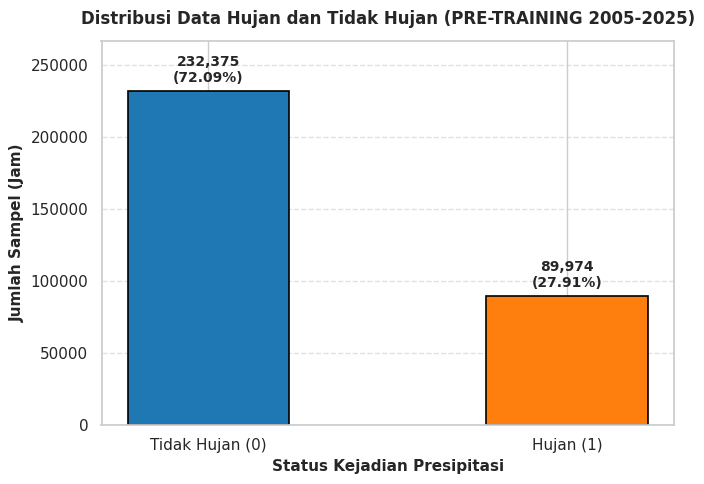

In [5]:
# Visualisasi Distribusi Hujan vs Tidak Hujan (PRE-TRAINING)
# Memplot persentase kejadian hujan (rainrate >= 0.2 mm/jam) pada data pre-training.
import matplotlib.pyplot as plt
import seaborn as sns

rain_count = int((df_hourly['rainrate'] > 0).sum())
no_rain_count = int((df_hourly['rainrate'] == 0).sum())
total_samples = rain_count + no_rain_count

plt.figure(figsize=(7, 5))
bars = plt.bar(['Tidak Hujan (0)', 'Hujan (1)'], [no_rain_count, rain_count], 
               color=['#1f77b4', '#ff7f0e'], width=0.45, edgecolor='black', linewidth=1.2)
plt.title('Distribusi Data Hujan dan Tidak Hujan (PRE-TRAINING 2005-2025)', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Jumlah Sampel (Jam)', fontsize=11, fontweight='bold')
plt.xlabel('Status Kejadian Presipitasi', fontsize=11, fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    pct = (yval / total_samples) * 100
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + (total_samples * 0.012),
             f'{yval:,}\n({pct:.2f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, max(no_rain_count, rain_count) * 1.15)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

plot_dir_01 = BASE_OUTPUT_DIR / 'plots'
plot_dir_01.mkdir(parents=True, exist_ok=True)
plot_path_01 = plot_dir_01 / '01_distribusi_data_hujan_pretraining.png'
plt.savefig(plot_path_01, dpi=300, bbox_inches='tight')
logger.info(f"Plot distribusi data pre-training disimpan: {plot_path_01}")
plt.show()
plt.close()


## Tahap 4: Rekayasa Fitur (*Feature Engineering*)

Sel ini meramu data mentah 1-jaman menjadi format 1-jaman yang siap ditelan model. Fitur-fitur canggih seperti **Tren 1 Jam** (*difference*) dihitung di sini, beserta nilai agregasi fitur konvektif tingkat lanjut (CAPE, K-Index) dari ERA5.

In [6]:
# Sel 5: Rekayasa Fitur Fisika Atmosfer
# Menghitung indeks diurnal harian dan fitur atmosfer penting seperti dewpoint depression.
def engineer_features(df_base):
    logger.info("Mengekstraksi fitur fisika & temporal...")

    cols_diff = ['temperature', 'dewpoint', 'pressure']
    for c in cols_diff:
        if c in df_base.columns:
            df_base[f'{c}_tendency_1h'] = df_base[c].diff()
            
    if 'temperature' in df_base.columns and 'dewpoint' in df_base.columns:
        df_base['dewpoint_depression'] = df_base['temperature'] - df_base['dewpoint']

    # Fitur waktu siklikal (cyclic time encoding)
    df_base['sin_hour']  = np.sin(2 * np.pi * df_base.index.hour / 24.0)
    df_base['cos_hour']  = np.cos(2 * np.pi * df_base.index.hour / 24.0)
    df_base['sin_month'] = np.sin(2 * np.pi * df_base.index.month / 12.0)
    df_base['cos_month'] = np.cos(2 * np.pi * df_base.index.month / 12.0)
    df_base['sin_doy']   = np.sin(2 * np.pi * df_base.index.dayofyear / 365.25)
    df_base['cos_doy']   = np.cos(2 * np.pi * df_base.index.dayofyear / 365.25)

    df = df_base.copy()
    df = df.dropna()
    logger.info(f"Dimensi akhir setelah rekayasa fitur: {df.shape}")
    return df


## Tahap 4.5: Persiapan Parameter LSTM

Sel ini mengatur ukuran jendela sekuens (*lookback window*) yang akan dibaca oleh memori LSTM.

In [7]:
# Sel 6: Setup Parameter Dasar & Split Data LSTM
# Memformat data menjadi array sekuensial 3D (samples, timesteps, features)
# menggunakan lookback window LOOKBACK=24 jam untuk melatih LSTM Dua Tahap.
import optuna
import gc
from tensorflow.keras import backend as K

logger.info(f"\n{'='*50}\nMEMULAI PERSIAPAN DATA SEKUENSIAL DUA TAHAP (LOOKBACK={LOOKBACK})\n{'='*50}")
evaluator = ModelEvaluator()

df_features = engineer_features(df_hourly)
# Target: curah hujan 1 jam ke depan
df_features['target_amount'] = df_features['rainrate'].shift(-1)
df_features = df_features.dropna()
df_features['target_occurrence'] = (df_features['target_amount'] >= RAIN_THRESHOLD).astype(int)

# 3. Data Split
if RUN_MODE == "PIPELINE_TEST":
    n = len(df_features)
    train_mask = np.arange(n) < int(n * 0.7)
    val_mask   = (np.arange(n) >= int(n * 0.7)) & (np.arange(n) < int(n * 0.9))
    test_mask  = np.arange(n) >= int(n * 0.9)
else:
    # Pembagian data berdasarkan tanggal
    train_mask = (df_features.index >= PRETRAIN__TRAIN_START) & (df_features.index <= PRETRAIN__TRAIN_END)
    val_mask   = (df_features.index >= PRETRAIN__VAL_START)   & (df_features.index < PRETRAIN__VAL_END)
    test_mask  = (df_features.index >= PRETRAIN__TEST_START)  & (df_features.index <= PRETRAIN__TEST_END)

X     = df_features.drop(columns=['target_amount', 'target_occurrence'])
y_occ = df_features['target_occurrence']
y_reg = df_features['target_amount']

scaler = MinMaxScaler()
scaler.fit(X[train_mask])
X_scaled = pd.DataFrame(scaler.transform(X), columns=X.columns, index=X.index)

import joblib
joblib.dump(scaler, evaluator.dirs['models'] / 'pretrain_scaler.pkl')
logger.info(f"Scaler di-fit pada {X[train_mask].shape[0]} sampel latih. Disimpan ke pretrain_scaler.pkl")

def make_3d(X_df, y_o, y_r, lookback):
    X_arr, yo_arr, yr_arr = [], [], []
    for i in range(len(X_df) - lookback + 1):
        X_arr.append(X_df.iloc[i:i+lookback].values)
        yo_arr.append(y_o.iloc[i+lookback-1])
        yr_arr.append(y_r.iloc[i+lookback-1])
    return (np.array(X_arr, dtype=np.float32),
            np.array(yo_arr, dtype=np.float32),
            np.array(yr_arr, dtype=np.float32))

X_tr_seq, y_tr_o, y_tr_r = make_3d(X_scaled[train_mask], y_occ[train_mask], y_reg[train_mask], LOOKBACK)
X_va_seq, y_va_o, y_va_r = make_3d(X_scaled[val_mask],   y_occ[val_mask],   y_reg[val_mask],   LOOKBACK)
X_te_seq, y_te_o, y_te_r = make_3d(X_scaled[test_mask],  y_occ[test_mask],  y_reg[test_mask],  LOOKBACK)

logger.info(f"Sequence shapes — Train: {X_tr_seq.shape}, Val: {X_va_seq.shape}, Test: {X_te_seq.shape}")
logger.info(f"Distribusi Hujan (Train): {y_tr_o.sum():.0f}/{len(y_tr_o)} ({100*y_tr_o.mean():.1f}%)")
logger.info(f"Distribusi Hujan (Val)  : {y_va_o.sum():.0f}/{len(y_va_o)} ({100*y_va_o.mean():.1f}%)")
logger.info(f"Distribusi Hujan (Test) : {y_te_o.sum():.0f}/{len(y_te_o)} ({100*y_te_o.mean():.1f}%)")

cek_proporsi_pretraining(X_tr_seq, y_tr_o, X_va_seq, y_va_o, X_te_seq, y_te_o)

# Alias eksplisit untuk evaluasi akhir
X_te_seq_pre = X_te_seq
y_te_o_pre   = y_te_o
y_te_r_pre   = y_te_r

2026-10-30 02:46:04,831 - INFO - 
MEMULAI PERSIAPAN DATA SEKUENSIAL DUA TAHAP (LOOKBACK=24)
2026-10-30 02:46:04,832 - INFO - Mengekstraksi fitur fisika & temporal...
2026-10-30 02:46:05,000 - INFO - Dimensi akhir setelah rekayasa fitur: (322327, 23)
2026-10-30 02:46:05,122 - INFO - Scaler di-fit pada 140233 sampel latih. Disimpan ke pretrain_scaler.pkl
2026-10-30 02:46:10,793 - INFO - Sequence shapes — Train: (140210, 24, 23), Val: (26219, 24, 23), Test: (17491, 24, 23)
2026-10-30 02:46:10,795 - INFO - Distribusi Hujan (Train): 41951/140210 (29.9%)
2026-10-30 02:46:10,796 - INFO - Distribusi Hujan (Val)  : 8010/26219 (30.6%)
2026-10-30 02:46:10,796 - INFO - Distribusi Hujan (Test) : 5541/17491 (31.7%)


Dataset Distribution (Pretraining)
Training samples: 140210
Validation samples: 26219
Testing samples: 17491
Rain samples: 55502
Non-rain samples: 128418
Rain percentage: 30.18%
Non-rain percentage: 69.82%
Positive/Negative ratio: 0.4322


## Tahap 5: Pelatihan Klasifikasi Hujan (Bayesian Optimization — Optuna TPE + HyperbandPruner)

Pada tahap ini, model Jaringan Saraf Tiruan LSTM dilatih untuk memprediksi **kejadian hujan** (probabilitas $\ge 0.2\text{ mm/jam}$) berdasarkan sekuens waktu 24 jam ke belakang.

### Spesifikasi Objektif Bayesian Optimization:
1. **Fungsi Objektif**: Memaksimalkan nilai **F1-Score** pada data validasi dengan pencarian ambang batas dinamis (*Dynamic Threshold Search* $\tau \in [0.20, 0.70]$).
2. **Penanganan Zero-Inflation**: Dataset cuaca tropis didominasi jam-jam kering (>85% jam tanpa hujan). Optimasi akurasi biasa akan menghasilkan model degenerate yang selalu memprediksi tidak hujan. F1-Score menuntut presisi dan recall tinggi pada kelas minoritas (hujan).
3. **Regularisasi L2 (Weight Decay)**: Mencegah saturasi gerbang *forget*, *input*, dan *output* pada sel LSTM.
4. **Hyperband Pruning Callback Mandiri**: Menghentikan trial yang tidak menjanjikan pada epoch 5, 10, atau 15 sebelum menghabiskan batas 30 epoch.

2026-10-30 02:46:10,843 - INFO - Memulai Bayesian Optimization Optuna untuk LSTM Classifier (TPE Multivariate + Hyperband)...
[I 2026-10-30 02:46:12,882] A new study created in RDB with name: lstm_classifier_bayesian
I0000 00:00:1793328377.281387      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793328377.288283      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
[I 2026-10-30 02:54:48,179] Trial 0 finished with value: 0.9464919641128251 and parameters: {'units_l1': 128, 'units_l2': 32, 'lr': 0.0007613783327152942, 'dropout': 0.1, 'batch_size': 64}. Best is trial 0 with value: 0.9464919641128251.
[I 2026-10-30 02:57:06,881] Trial 1 finished with value: 0.9412448347107438 and parameters: {'units_l1'

Epoch 1/60
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 0.3172 - precision: 0.8340 - recall: 0.6612 - val_loss: 0.1712 - val_precision: 0.9257 - val_recall: 0.8704 - learning_rate: 7.6138e-04
Epoch 2/60
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - loss: 0.1489 - precision: 0.9456 - recall: 0.8834 - val_loss: 0.1419 - val_precision: 0.9676 - val_recall: 0.8724 - learning_rate: 7.6138e-04
Epoch 3/60
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - loss: 0.1245 - precision: 0.9629 - recall: 0.9055 - val_loss: 0.1308 - val_precision: 0.9632 - val_recall: 0.9089 - learning_rate: 7.6138e-04
Epoch 4/60
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - loss: 0.1171 - precision: 0.9709 - recall: 0.9102 - val_loss: 0.1177 - val_precision: 0.9706 - val_recall: 0.9120 - learning_rate: 7.6138e-04
Epoch 5/60
2191/2191 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - loss: 0.1120 - precision: 0.9745 - recall: 0.9132 - val_loss: 0.1131 - val_precision: 0.9787 - val_recall: 0.9101 - learning_rate: 7.6138e-04
Epoch

2026-10-30 05:10:55,776 - INFO - Plot training loss classifier disimpan: outputs_lstm_bayesian/plots/02_training_loss_classifier.png


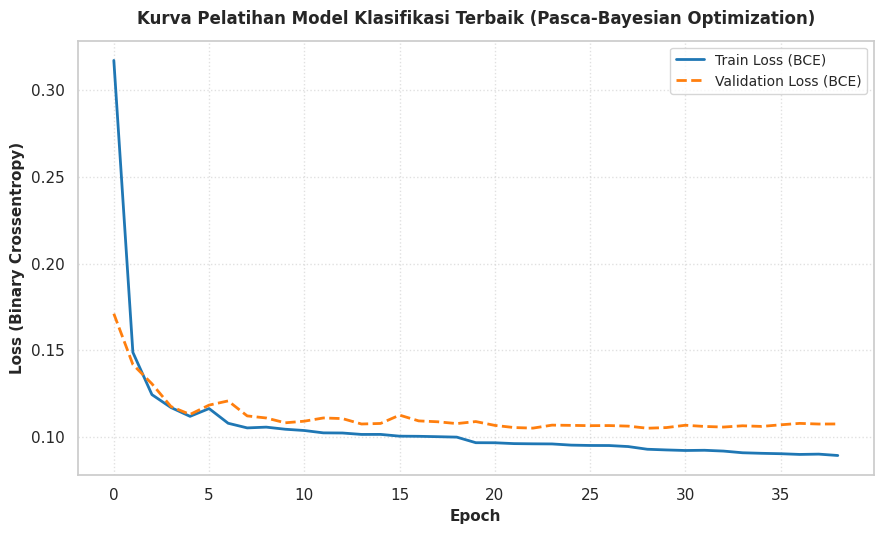

2026-10-30 05:10:56,352 - INFO - Arsitektur Classifier disimpan: outputs_lstm_bayesian/models/classifier/model_architecture_clf.png


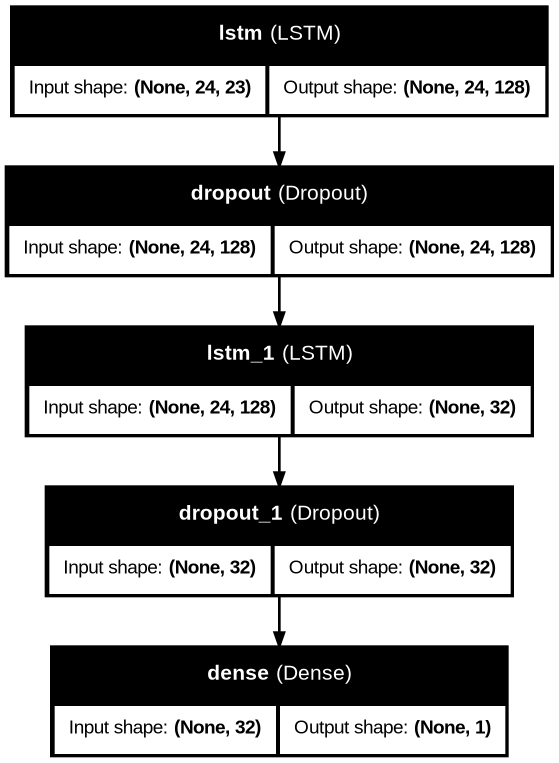

2026-10-30 05:10:59,249 - INFO - [Calibrator Selection] Brier scores - Raw: 0.0273, Platt: 0.0284, Isotonic: 0.0270
2026-10-30 05:10:59,252 - INFO - [Calibrator Selection] Selected Isotonic Calibrator
2026-10-30 05:10:59,351 - INFO - Ambang Batas Klasifikasi Optimal (Pre-training): 0.48
2026-10-30 05:10:59,353 - INFO - Pre-training Classifier dengan Bayesian Optimization selesai!


In [8]:
from tensorflow import keras
# Sel 7: Bayesian Optimization untuk Classifier LSTM
# TPE multivariate + HyperbandPruner + Search Space Diperluas + Regularisasi L2
import optuna
from optuna.pruners import HyperbandPruner
from tensorflow.keras.layers import LSTM, Dropout, Dense, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import gc
from tensorflow.keras import backend as K
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, brier_score_loss
import joblib
import warnings

# Filter peringatan eksperimental Optuna untuk menjaga kebersihan log
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# ==============================================================================
# Native Optuna Keras Pruning Callback (Zero-Dependency)
# Kompatibel penuh dengan Optuna 3.x dan 4.x tanpa memerlukan modul eksternal
# ==============================================================================
class OptunaKerasPruningCallback(tf.keras.callbacks.Callback):
    """Custom Keras Callback untuk integrasi pemangkasan otomatis HyperbandPruner."""
    def __init__(self, trial, monitor='val_loss'):
        super().__init__()
        self.trial = trial
        self.monitor = monitor

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        val = logs.get(self.monitor)
        if val is not None:
            self.trial.report(float(val), step=epoch)
            if self.trial.should_prune():
                message = f"Trial {self.trial.number} dipangkas pada epoch {epoch} ({self.monitor}={val:.4f})"
                raise optuna.TrialPruned(message)

def build_lstm_clf(lookback, units_l1, units_l2, lr, dropout):
    model = Sequential([
        Input(shape=(lookback, X.shape[1])),
        LSTM(units_l1, return_sequences=True),
        Dropout(dropout),
        LSTM(units_l2, return_sequences=False),
        Dropout(dropout),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=Adam(learning_rate=lr), 
        loss='binary_crossentropy', 
        metrics=[
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall')
        ]
    )
    return model

def objective_clf(trial):
    K.clear_session()
    gc.collect()
    units_l1     = trial.suggest_categorical('units_l1', SEARCH_UNITS_L1)
    units_l2     = trial.suggest_categorical('units_l2', SEARCH_UNITS_L2)
    lr           = trial.suggest_float('lr', SEARCH_LR_MIN, SEARCH_LR_MAX, log=True)
    dropout      = trial.suggest_categorical('dropout', SEARCH_DROPOUT)
    batch_size   = trial.suggest_categorical('batch_size', SEARCH_BATCH)
    
    model = build_lstm_clf(LOOKBACK, units_l1, units_l2, lr, dropout)
    es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    pruning_cb = OptunaKerasPruningCallback(trial, monitor='val_loss')
    
    model.fit(
        X_tr_seq, y_tr_o, 
        validation_data=(X_va_seq, y_va_o),
        epochs=HYPERBAND_MAX_RESOURCE, 
        batch_size=batch_size, 
        callbacks=[es, pruning_cb], 
        verbose=0
    )
    
    val_prob = model.predict(X_va_seq, verbose=0).flatten()
    # Dynamic threshold search — pilih threshold dengan F1 terbaik di validasi
    best_f1_trial, best_thresh_trial = 0.0, 0.5
    for _t in np.arange(0.20, 0.70, 0.02):
        _preds = (val_prob >= _t).astype(int)
        _f1 = f1_score(y_va_o, _preds, zero_division=0)
        if _f1 > best_f1_trial:
            best_f1_trial, best_thresh_trial = _f1, _t
            
    trial.set_user_attr('best_threshold', float(best_thresh_trial))
    return best_f1_trial

logger.info("Memulai Bayesian Optimization Optuna untuk LSTM Classifier (TPE Multivariate + Hyperband)...")
optuna.logging.set_verbosity(optuna.logging.INFO)

import os
db_path = evaluator.dirs['models'] / 'optuna_lstm_bayesian.db'
os.makedirs(db_path.parent, exist_ok=True)
storage_url = f"sqlite:///{db_path.as_posix()}"

study_clf = optuna.create_study(
    study_name="lstm_classifier_bayesian",
    sampler=optuna.samplers.TPESampler(
        seed=SEED, 
        n_startup_trials=BAYESIAN_N_STARTUP_TRIALS,
        gamma=lambda n: min(int(np.ceil(BAYESIAN_GAMMA * n)), 25),
        multivariate=True, 
        warn_independent_sampling=False
    ),
    pruner=HyperbandPruner(
        min_resource=HYPERBAND_MIN_RESOURCE,
        max_resource=HYPERBAND_MAX_RESOURCE, 
        reduction_factor=HYPERBAND_REDUCTION_FACTOR
    ),
    storage=storage_url, 
    direction='maximize', 
    load_if_exists=True
)
study_clf.optimize(objective_clf, n_trials=OPTUNA_TRIALS)

best_clf_params = study_clf.best_params
logger.info(f"Parameter terbaik Classifier (Bayesian TPE): {best_clf_params}")

# Ekspor tabel riwayat seluruh trial untuk dokumentasi penelitian
df_trials_clf = study_clf.trials_dataframe()
df_trials_clf.to_csv(evaluator.dirs['models_clf'] / 'optuna_trials_clf.csv', index=False)
logger.info(f"Riwayat trial classifier disimpan ke: {evaluator.dirs['models_clf'] / 'optuna_trials_clf.csv'}")

K.clear_session()
gc.collect()

# Pelatihan akhir model terbaik dengan epoch penuh (EPOCHS_BEST)
clf_best = build_lstm_clf(
    LOOKBACK,
    best_clf_params['units_l1'],
    best_clf_params['units_l2'],
    best_clf_params['lr'],
    best_clf_params['dropout']
)

clf_ckpt_path = str(evaluator.dirs['models_clf'] / 'best_lstm_occ_ckpt.keras')
es        = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
ckpt      = ModelCheckpoint(clf_ckpt_path, monitor='val_loss', save_best_only=True, verbose=0)

history_clf = clf_best.fit(
    X_tr_seq, y_tr_o,
    validation_data=(X_va_seq, y_va_o),
    epochs=EPOCHS_BEST,
    batch_size=best_clf_params['batch_size'],
    callbacks=[es, reduce_lr, ckpt],
    verbose=1
)

plt.figure(figsize=(9, 5.5))
plt.plot(history_clf.history['loss'], label='Train Loss (BCE)', color='#1f77b4', linewidth=2.0)
plt.plot(history_clf.history['val_loss'], label='Validation Loss (BCE)', color='#ff7f0e', linewidth=2.0, linestyle='--')
plt.title('Kurva Pelatihan Model Klasifikasi Terbaik (Pasca-Bayesian Optimization)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Epoch', fontsize=11, fontweight='bold')
plt.ylabel('Loss (Binary Crossentropy)', fontsize=11, fontweight='bold')
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
p02_path = evaluator.dirs['plots'] / '02_training_loss_classifier.png'
plt.savefig(p02_path, dpi=300, bbox_inches='tight')
plt.savefig(evaluator.dirs['plots'] / 'training_loss_clf.png', dpi=300, bbox_inches='tight')
logger.info(f'Plot training loss classifier disimpan: {p02_path}')
plt.show()
plt.close()

clf_best.save(evaluator.dirs['models_clf'] / 'best_lstm_occ.keras')

# Plot arsitektur model (Graphviz)
try:
    from tensorflow.keras.utils import plot_model
    from IPython.display import Image, display
    _arch_path_clf = str(evaluator.dirs['models_clf'] / 'model_architecture_clf.png')
    plot_model(clf_best, to_file=_arch_path_clf, show_shapes=True, show_layer_names=True, dpi=96)
    logger.info(f"Arsitektur Classifier disimpan: {_arch_path_clf}")
    display(Image(_arch_path_clf))
except Exception as _e:
    logger.warning(f"plot_model tidak tersedia (Graphviz belum terpasang): {_e}")

# Kalibrasi Probabilitas — Isotonic vs Platt Scaling
val_probs_uncal = clf_best.predict(X_va_seq, verbose=0).flatten()
best_calibrator_pretrain, cal_method_pretrain = fit_best_calibrator(y_va_o, val_probs_uncal)

if best_calibrator_pretrain is not None:
    joblib.dump(best_calibrator_pretrain, evaluator.dirs['models_cal'] / 'isotonic_calibrator.pkl')

iso_temp = IsotonicRegression(out_of_bounds='clip').fit(val_probs_uncal, y_va_o)
brier_iso = brier_score_loss(y_va_o, iso_temp.predict(val_probs_uncal))
platt_temp = LogisticRegression().fit(val_probs_uncal.reshape(-1, 1), y_va_o)
brier_platt = brier_score_loss(y_va_o, platt_temp.predict_proba(val_probs_uncal.reshape(-1, 1))[:, 1])

joblib.dump({'method': cal_method_pretrain, 'brier_iso': brier_iso, 'brier_platt': brier_platt},
            evaluator.dirs['models_cal'] / 'calibration_meta.pkl')

best_threshold_pretrain = study_clf.best_trial.user_attrs.get('best_threshold', 0.5)
joblib.dump(best_threshold_pretrain, evaluator.dirs['models_clf'] / 'best_threshold_pretrain.pkl')
logger.info(f"Ambang Batas Klasifikasi Optimal (Pre-training): {best_threshold_pretrain:.2f}")
logger.info("Pre-training Classifier dengan Bayesian Optimization selesai!")

### 5.1 Analisis Diagnostik & Visualisasi Tingkat Lanjut Bayesian Optimization — Classifier (BiLSTM)

Bagian ini menyajikan rangkaian analisis visual menyeluruh dari proses *Bayesian Optimization*:

#### Visualisasi 1: Diagnostik Inti Konvergensi (4 Panel - `bayesian_diagnostics_clf.png`)
1. **Kurva Konvergensi (*Optimization History*)**: Memperlihatkan transisi dari fase eksplorasi acak (*startup exploration*, trial 1–15) menuju fase eksploitasi terarah Bayesian TPE (trial 16–50) dengan garis kumulatif terbaik (*running best*).
2. **Derajat Kepentingan Hiperparameter (*fANOVA Importances*)**: Menghitung kontribusi varians masing-masing parameter terhadap capaian F1-Score.
3. **Lanskap Interaksi 2D (*Response Surface*)**: Memetakan interaksi non-linier antara *Learning Rate* dan *Batch Size*.
4. **Efisiensi Alokasi Komputasi (*Hyperband Successive Halving*)**: Menghitung rasio trial sukses versus yang dipangkas lebih awal (*early pruned*).

#### Visualisasi 2: Analisis Lanjutan TPE Parzen Kernel & Koordinat Paralel (`bayesian_advanced_tpe_analysis_clf.png`)
1. **Estimasi Densitas Kernel Parzen TPE ($\ell(x)$ vs $g(x)$)**: Memvisualisasikan kurva densitas probabilitas non-parametrik yang dibangun oleh TPE untuk memisahkan 20% trial terbaik $\ell(x)$ dari 80% trial lainnya $g(x)$, serta kurva rasio *Expected Improvement* $\frac{\ell(x)}{g(x)}$.
2. **Grafik Koordinat Paralel (*Parallel Coordinates Plot*)**: Menelusuri seluruh dimensi hiperparameter yang dinormalisasi untuk melihat konvergensi lintasan konfigurasi elit (*Top 20%*) ke wilayah optimal.
3. **Grafik *Marginal Slices***: Memperlihatkan kepadatan sampling Bayesian pada dimensi kapasitas unit LSTM dan *dropout*.

2026-10-30 05:11:00,882 - INFO - Menghasilkan visualisasi diagnostik terpisah Bayesian Optimization untuk Classifier...
2026-10-30 05:11:01,373 - INFO - Plot diagnostik 03 disimpan: outputs_lstm_bayesian/plots/03_bayesian_clf_konvergensi_optimasi.png


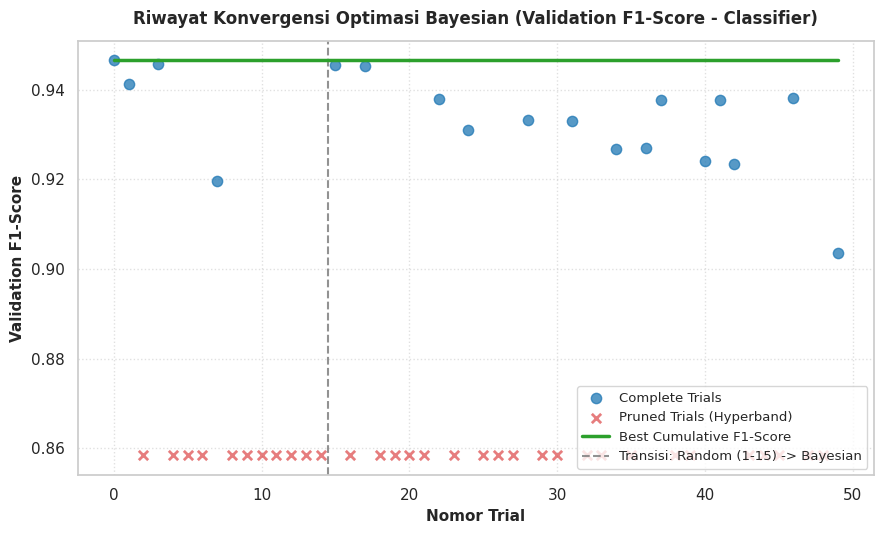

2026-10-30 05:11:01,906 - INFO - Plot diagnostik 04 disimpan: outputs_lstm_bayesian/plots/04_bayesian_clf_kepentingan_hiperparameter_fanova.png


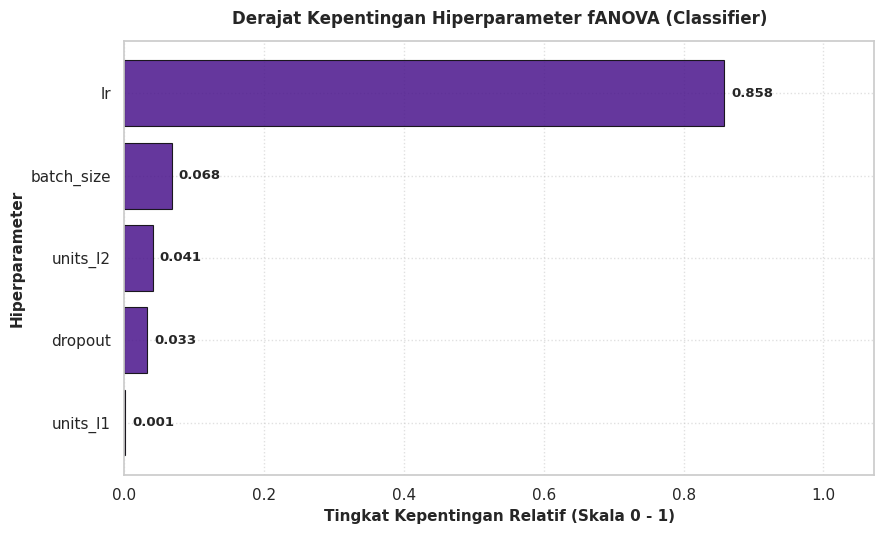

2026-10-30 05:11:02,814 - INFO - Plot diagnostik 05 disimpan: outputs_lstm_bayesian/plots/05_bayesian_clf_response_surface_lr_batch.png


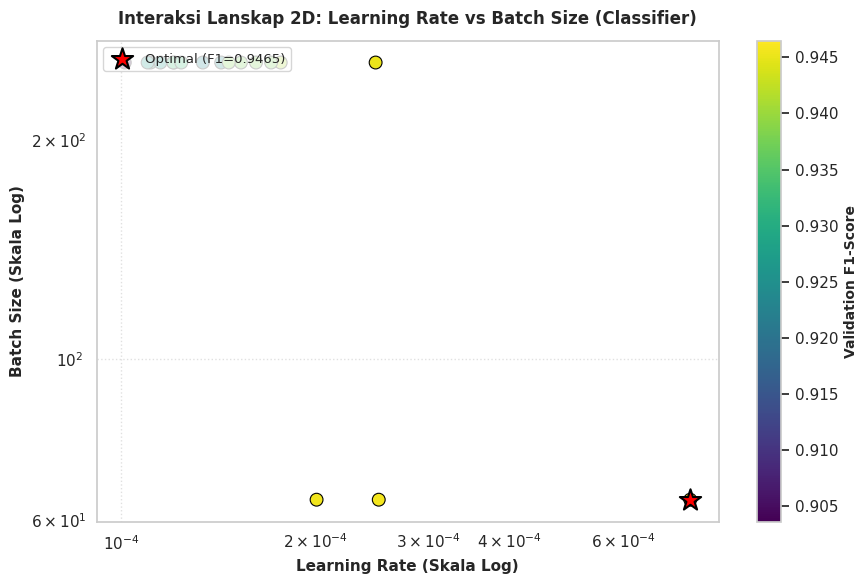

2026-10-30 05:11:03,345 - INFO - Plot diagnostik 06 disimpan: outputs_lstm_bayesian/plots/06_bayesian_clf_efisiensi_pruning_hyperband.png


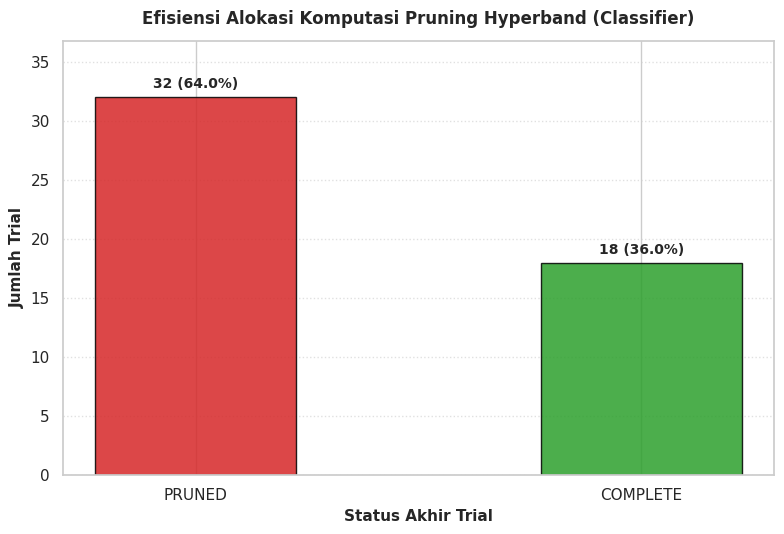

2026-10-30 05:11:04,043 - INFO - Plot diagnostik 07 disimpan: outputs_lstm_bayesian/plots/07_bayesian_clf_densitas_parzen_tpe_lr.png


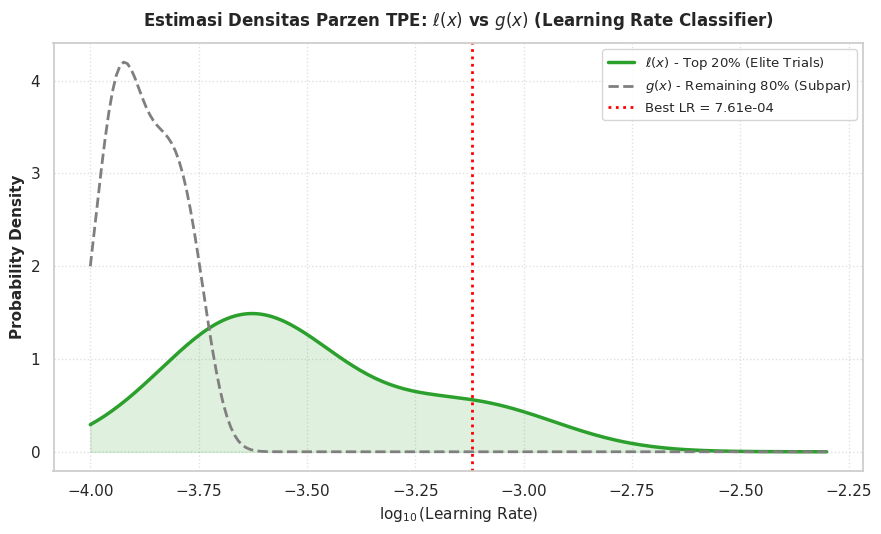

2026-10-30 05:11:04,792 - INFO - Plot diagnostik 08 disimpan: outputs_lstm_bayesian/plots/08_bayesian_clf_koordinat_paralel.png


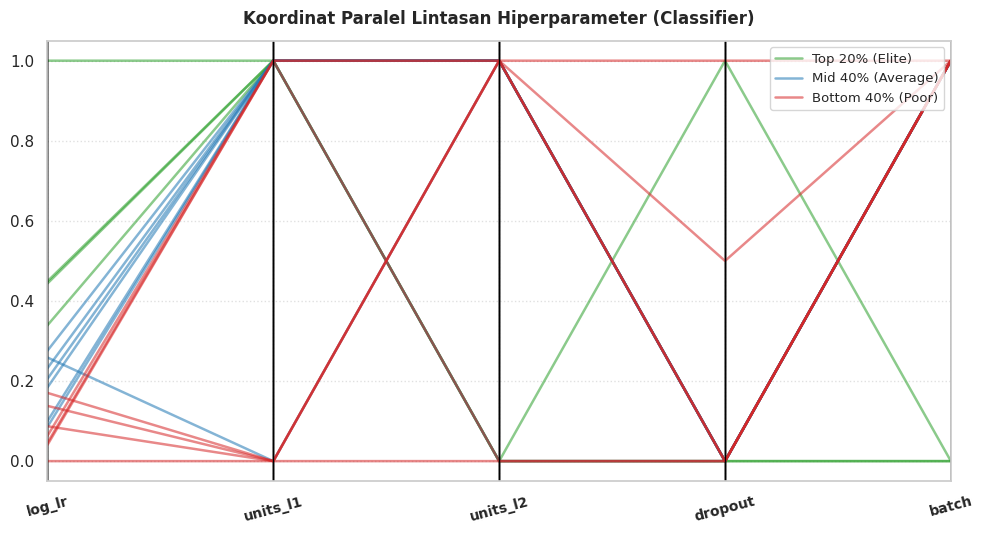

2026-10-30 05:11:05,291 - INFO - Plot diagnostik 09 disimpan: outputs_lstm_bayesian/plots/09_bayesian_clf_marginal_slice_units_l1.png


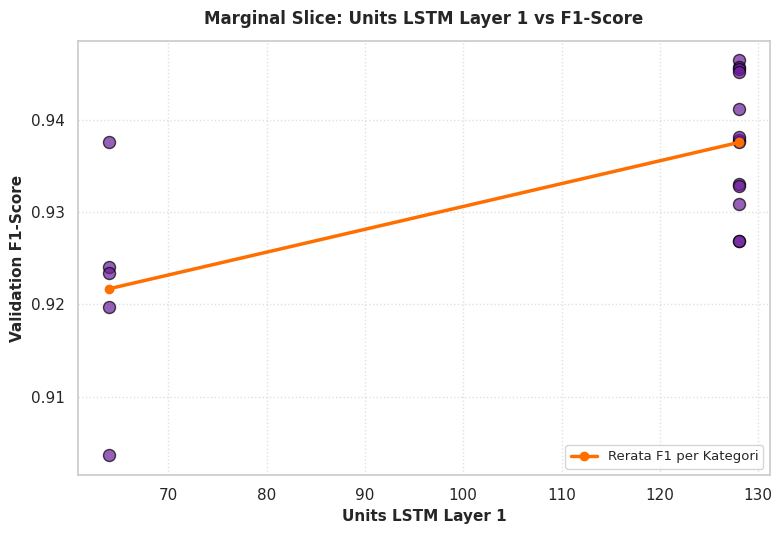

2026-10-30 05:11:05,762 - INFO - Plot diagnostik 10 disimpan: outputs_lstm_bayesian/plots/10_bayesian_clf_marginal_slice_dropout.png


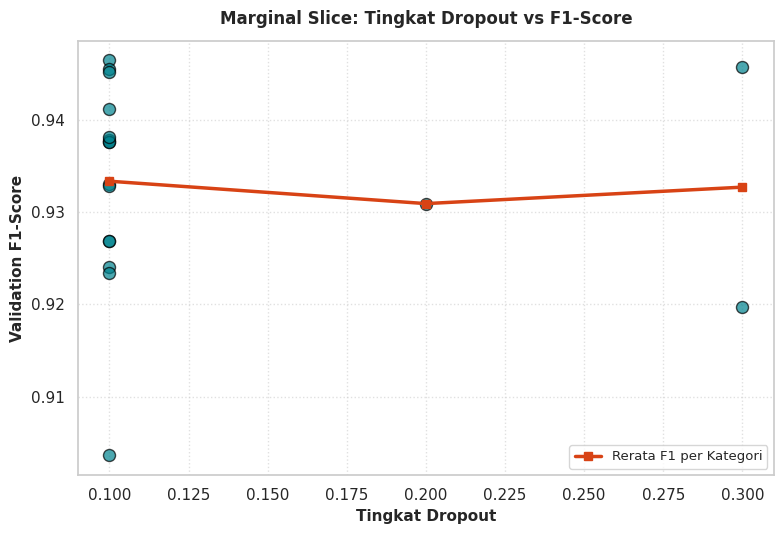

2026-10-30 05:11:05,869 - INFO - Seluruh 8 plot diagnostik terpisah Bayesian Classifier berhasil diekspor (300 DPI)!


In [9]:
# Sel 7.5: Visualisasi Diagnostik & Analisis Lanjutan Bayesian Optimization (Classifier)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import optuna
from scipy.stats import gaussian_kde
from pandas.plotting import parallel_coordinates

logger.info("Menghasilkan visualisasi diagnostik terpisah Bayesian Optimization untuk Classifier...")

df_clf_trials = study_clf.trials_dataframe()
df_clf_completed = df_clf_trials[df_clf_trials['state'] == 'COMPLETE'].copy()
df_clf_pruned    = df_clf_trials[df_clf_trials['state'] == 'PRUNED'].copy()
plot_dir_clf = evaluator.dirs['plots']
plot_dir_clf.mkdir(parents=True, exist_ok=True)

# ==============================================================================
# PLOT 03: OPTIMIZATION HISTORY & CONVERGENCE (CLASSIFIER)
# ==============================================================================
plt.figure(figsize=(9, 5.5))
trial_nums = df_clf_trials['number']
trial_vals = df_clf_trials['value']

running_best = []
current_max = -np.inf
for v in trial_vals:
    if pd.notna(v) and v > current_max:
        current_max = v
    running_best.append(current_max if current_max != -np.inf else np.nan)

plt.scatter(df_clf_completed['number'], df_clf_completed['value'], color='#1f77b4', alpha=0.75, s=55, label='Complete Trials', zorder=3)
if len(df_clf_pruned) > 0:
    min_val = df_clf_completed['value'].min() if len(df_clf_completed) > 0 else 0.0
    plt.scatter(df_clf_pruned['number'], [min_val * 0.95]*len(df_clf_pruned), 
                color='#d62728', marker='x', alpha=0.6, s=45, label='Pruned Trials (Hyperband)', zorder=2)
plt.plot(trial_nums, running_best, color='#2ca02c', linewidth=2.5, label='Best Cumulative F1-Score', zorder=4)
plt.axvline(x=BAYESIAN_N_STARTUP_TRIALS - 0.5, color='#7f7f7f', linestyle='--', linewidth=1.5, alpha=0.85,
            label=f'Transisi: Random (1-{BAYESIAN_N_STARTUP_TRIALS}) -> Bayesian')
plt.title('Riwayat Konvergensi Optimasi Bayesian (Validation F1-Score - Classifier)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Nomor Trial', fontsize=11, fontweight='bold')
plt.ylabel('Validation F1-Score', fontsize=11, fontweight='bold')
plt.legend(loc='lower right', frameon=True, fontsize=9.5)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
p03_path = plot_dir_clf / '03_bayesian_clf_konvergensi_optimasi.png'
plt.savefig(p03_path, dpi=300, bbox_inches='tight')
logger.info(f"Plot diagnostik 03 disimpan: {p03_path}")
plt.show()
plt.close()

# ==============================================================================
# PLOT 04: HYPERPARAMETER IMPORTANCES (fANOVA - CLASSIFIER)
# ==============================================================================
plt.figure(figsize=(9, 5.5))
try:
    param_importances = optuna.importance.get_param_importances(study_clf)
    params_sorted = list(param_importances.keys())[::-1]
    importances_sorted = [param_importances[k] for k in params_sorted]
    
    bars = plt.barh(params_sorted, importances_sorted, color='#4a148c', alpha=0.85, edgecolor='black', linewidth=0.8)
    plt.title('Derajat Kepentingan Hiperparameter fANOVA (Classifier)', fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('Tingkat Kepentingan Relatif (Skala 0 - 1)', fontsize=11, fontweight='bold')
    plt.ylabel('Hiperparameter', fontsize=11, fontweight='bold')
    for bar in bars:
        plt.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.3f}',
                 va='center', ha='left', fontsize=9.5, fontweight='bold')
    plt.xlim(0, max(importances_sorted) * 1.25 if importances_sorted else 1.0)
except Exception as e:
    plt.text(0.5, 0.5, f"Evaluasi Importance: {e}", ha='center', va='center')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
p04_path = plot_dir_clf / '04_bayesian_clf_kepentingan_hiperparameter_fanova.png'
plt.savefig(p04_path, dpi=300, bbox_inches='tight')
logger.info(f"Plot diagnostik 04 disimpan: {p04_path}")
plt.show()
plt.close()

# ==============================================================================
# PLOT 05: 2D RESPONSE SURFACE (LEARNING RATE VS BATCH SIZE - CLASSIFIER)
# ==============================================================================
plt.figure(figsize=(9, 6))
if 'params_lr' in df_clf_completed.columns and 'params_batch_size' in df_clf_completed.columns:
    sc = plt.scatter(
        df_clf_completed['params_lr'],
        df_clf_completed['params_batch_size'],
        c=df_clf_completed['value'],
        cmap='viridis',
        s=85,
        edgecolors='black',
        linewidth=0.8,
        zorder=3
    )
    cbar = plt.colorbar(sc)
    cbar.set_label('Validation F1-Score', fontsize=10, fontweight='bold')
    plt.xscale('log')
    plt.yscale('log')
    best_t = study_clf.best_trial
    plt.scatter(
        best_t.params['lr'], best_t.params['batch_size'],
        color='red', marker='*', s=260, edgecolor='black', linewidth=1.5,
        label=f'Optimal (F1={study_clf.best_value:.4f})', zorder=5
    )
    plt.title('Interaksi Lanskap 2D: Learning Rate vs Batch Size (Classifier)', fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('Learning Rate (Skala Log)', fontsize=11, fontweight='bold')
    plt.ylabel('Batch Size (Skala Log)', fontsize=11, fontweight='bold')
    plt.legend(loc='upper left', frameon=True, fontsize=9.5)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
p05_path = plot_dir_clf / '05_bayesian_clf_response_surface_lr_batch.png'
plt.savefig(p05_path, dpi=300, bbox_inches='tight')
logger.info(f"Plot diagnostik 05 disimpan: {p05_path}")
plt.show()
plt.close()

# ==============================================================================
# PLOT 06: HYPERBAND PRUNING DISTRIBUTION (CLASSIFIER)
# ==============================================================================
plt.figure(figsize=(8, 5.5))
state_counts = df_clf_trials['state'].value_counts()
colors = ['#2ca02c' if s == 'COMPLETE' else '#d62728' for s in state_counts.index]
bars4 = plt.bar(state_counts.index, state_counts.values, color=colors, alpha=0.85, edgecolor='black', linewidth=1.0, width=0.45)
plt.title('Efisiensi Alokasi Komputasi Pruning Hyperband (Classifier)', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Jumlah Trial', fontsize=11, fontweight='bold')
plt.xlabel('Status Akhir Trial', fontsize=11, fontweight='bold')
for bar in bars4:
    height = bar.get_height()
    pct = (height / len(df_clf_trials)) * 100
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.5, f'{height} ({pct:.1f}%)',
             ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.ylim(0, max(state_counts.values) * 1.15)
plt.grid(True, axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
p06_path = plot_dir_clf / '06_bayesian_clf_efisiensi_pruning_hyperband.png'
plt.savefig(p06_path, dpi=300, bbox_inches='tight')
logger.info(f"Plot diagnostik 06 disimpan: {p06_path}")
plt.show()
plt.close()

# ==============================================================================
# PLOT 07: TPE PARZEN KERNEL DENSITY ESTIMATION: l(x) vs g(x) (CLASSIFIER)
# ==============================================================================
plt.figure(figsize=(9, 5.5))
if len(df_clf_completed) >= 5 and 'params_lr' in df_clf_completed.columns:
    q20 = df_clf_completed['value'].quantile(0.80)
    top_trials = df_clf_completed[df_clf_completed['value'] >= q20]
    rest_trials = df_clf_completed[df_clf_completed['value'] < q20]
    
    log_lr_top = np.log10(top_trials['params_lr'])
    log_lr_rest = np.log10(rest_trials['params_lr'])
    x_grid = np.linspace(np.log10(SEARCH_LR_MIN), np.log10(SEARCH_LR_MAX), 200)
    try:
        kde_top = gaussian_kde(log_lr_top)
        kde_rest = gaussian_kde(log_lr_rest)
        dens_top = kde_top(x_grid)
        dens_rest = kde_rest(x_grid)
        
        plt.plot(x_grid, dens_top, label=r'$\ell(x)$ - Top 20% (Elite Trials)', color='#2ca02c', lw=2.5)
        plt.fill_between(x_grid, 0, dens_top, color='#2ca02c', alpha=0.15)
        plt.plot(x_grid, dens_rest, label=r'$g(x)$ - Remaining 80% (Subpar)', color='#7f7f7f', linestyle='--', lw=2.0)
        plt.axvline(x=np.log10(study_clf.best_params['lr']), color='red', linestyle=':', lw=2,
                    label=f"Best LR = {study_clf.best_params['lr']:.2e}")
        plt.title(r'Estimasi Densitas Parzen TPE: $\ell(x)$ vs $g(x)$ (Learning Rate Classifier)', fontsize=12, fontweight='bold', pad=12)
        plt.xlabel(r'$\log_{10}(\text{Learning Rate})$', fontsize=11, fontweight='bold')
        plt.ylabel('Probability Density', fontsize=11, fontweight='bold')
        plt.legend(loc='upper right', frameon=True, fontsize=9.5)
    except Exception as _e_kde:
        plt.text(0.5, 0.5, f"KDE memerlukan variasi trial: {_e_kde}", ha='center', va='center')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
p07_path = plot_dir_clf / '07_bayesian_clf_densitas_parzen_tpe_lr.png'
plt.savefig(p07_path, dpi=300, bbox_inches='tight')
logger.info(f"Plot diagnostik 07 disimpan: {p07_path}")
plt.show()
plt.close()

# ==============================================================================
# PLOT 08: PARALLEL COORDINATES PLOT (CLASSIFIER)
# ==============================================================================
plt.figure(figsize=(10, 5.5))
if len(df_clf_completed) >= 3:
    norm_df = pd.DataFrame()
    norm_df['log_lr'] = np.log10(df_clf_completed['params_lr'])
    norm_df['units_l1'] = df_clf_completed['params_units_l1']
    norm_df['units_l2'] = df_clf_completed['params_units_l2']
    norm_df['dropout'] = df_clf_completed['params_dropout']
    norm_df['batch'] = df_clf_completed['params_batch_size']
    if 'params_weight_decay' in df_clf_completed.columns:
        norm_df['log_wd'] = np.log10(df_clf_completed['params_weight_decay'])

    q_top = df_clf_completed['value'].quantile(0.80)
    q_mid = df_clf_completed['value'].quantile(0.40)
    def assign_tier(val):
        if val >= q_top: return 'Top 20% (Elite)'
        elif val >= q_mid: return 'Mid 40% (Average)'
        else: return 'Bottom 40% (Poor)'
    norm_df['Tier'] = df_clf_completed['value'].apply(assign_tier)

    feat_cols = [c for c in norm_df.columns if c != 'Tier']
    for col in feat_cols:
        cmin, cmax = norm_df[col].min(), norm_df[col].max()
        norm_df[col] = (norm_df[col] - cmin) / (cmax - cmin + 1e-9)

    color_map = {'Top 20% (Elite)': '#2ca02c', 'Mid 40% (Average)': '#1f77b4', 'Bottom 40% (Poor)': '#d62728'}
    for tier, col in color_map.items():
        sub = norm_df[norm_df['Tier'] == tier]
        if len(sub) > 0:
            parallel_coordinates(sub, 'Tier', color=[col], alpha=0.55, linewidth=1.8)
    plt.title('Koordinat Paralel Lintasan Hiperparameter (Classifier)', fontsize=12, fontweight='bold', pad=12)
    plt.legend(loc='upper right', frameon=True, fontsize=9.5)
    plt.xticks(rotation=15, fontsize=10, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
p08_path = plot_dir_clf / '08_bayesian_clf_koordinat_paralel.png'
plt.savefig(p08_path, dpi=300, bbox_inches='tight')
logger.info(f"Plot diagnostik 08 disimpan: {p08_path}")
plt.show()
plt.close()

# ==============================================================================
# PLOT 09: MARGINAL SLICE: UNITS LSTM LAYER 1 VS F1 (CLASSIFIER)
# ==============================================================================
plt.figure(figsize=(8, 5.5))
if 'params_units_l1' in df_clf_completed.columns:
    plt.scatter(df_clf_completed['params_units_l1'], df_clf_completed['value'], color='#6a1b9a', s=75, alpha=0.7, edgecolors='black')
    means_l1 = df_clf_completed.groupby('params_units_l1')['value'].mean()
    plt.plot(means_l1.index, means_l1.values, color='#ff6f00', marker='o', lw=2.5, label='Rerata F1 per Kategori')
    plt.title('Marginal Slice: Units LSTM Layer 1 vs F1-Score', fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('Units LSTM Layer 1', fontsize=11, fontweight='bold')
    plt.ylabel('Validation F1-Score', fontsize=11, fontweight='bold')
    plt.legend(loc='lower right', frameon=True, fontsize=9.5)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
p09_path = plot_dir_clf / '09_bayesian_clf_marginal_slice_units_l1.png'
plt.savefig(p09_path, dpi=300, bbox_inches='tight')
logger.info(f"Plot diagnostik 09 disimpan: {p09_path}")
plt.show()
plt.close()

# ==============================================================================
# PLOT 10: MARGINAL SLICE: DROPOUT RATE VS F1 (CLASSIFIER)
# ==============================================================================
plt.figure(figsize=(8, 5.5))
if 'params_dropout' in df_clf_completed.columns:
    plt.scatter(df_clf_completed['params_dropout'], df_clf_completed['value'], color='#00838f', s=75, alpha=0.7, edgecolors='black')
    means_do = df_clf_completed.groupby('params_dropout')['value'].mean()
    plt.plot(means_do.index, means_do.values, color='#d84315', marker='s', lw=2.5, label='Rerata F1 per Kategori')
    plt.title('Marginal Slice: Tingkat Dropout vs F1-Score', fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('Tingkat Dropout', fontsize=11, fontweight='bold')
    plt.ylabel('Validation F1-Score', fontsize=11, fontweight='bold')
    plt.legend(loc='lower right', frameon=True, fontsize=9.5)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
p10_path = plot_dir_clf / '10_bayesian_clf_marginal_slice_dropout.png'
plt.savefig(p10_path, dpi=300, bbox_inches='tight')
logger.info(f"Plot diagnostik 10 disimpan: {p10_path}")
plt.show()
plt.close()

logger.info("Seluruh 8 plot diagnostik terpisah Bayesian Classifier berhasil diekspor (300 DPI)!")


## Tahap 6: Pelatihan Regresi Intensitas (Bayesian Optimization — Optuna TPE + HyperbandPruner)

Setelah model klasifikasi mengonfirmasi terjadinya hujan, model *Regressor* ini bertugas memprediksi **intensitas curah hujan** (dalam satuan milimeter per jam) pada sampel-sampel yang memiliki intensitas positif.

### Spesifikasi Objektif Bayesian Optimization:
1. **Transformasi Logaritmik**: Target hujan ditransformasi dengan $y_{\text{reg}} = \log(1 + y)$ untuk menstabilkan varians dan mengurangi sensitivitas terhadap *outlier* presipitasi ekstrem.
2. **Fungsi Objektif**: Meminimalkan nilai *Mean Squared Error (MSE)* pada data validasi.
3. **Regularisasi L2 (Weight Decay)**: Mencegah *overfitting* pada sampel hujan yang relatif lebih sedikit dibanding sampel kering.
4. **Hyperband Pruning Callback Mandiri**: Mengeliminasi arsitektur regresi yang divergen pada tahap awal pelatihan.

2026-10-30 05:11:07,251 - INFO - Memulai Bayesian Optimization Optuna untuk LSTM Regressor (TPE Multivariate + Hyperband)...
[I 2026-10-30 05:11:07,372] A new study created in RDB with name: lstm_regressor_bayesian
[I 2026-10-30 05:13:34,264] Trial 0 finished with value: 0.005622805096209049 and parameters: {'units_l1': 128, 'units_l2': 32, 'lr': 0.0007613783327152942, 'dropout': 0.1, 'batch_size': 64}. Best is trial 0 with value: 0.005622805096209049.
[I 2026-10-30 05:14:00,271] Trial 1 pruned. Trial 1 dipangkas pada epoch 15 (val_loss=0.0219)
[I 2026-10-30 05:16:25,931] Trial 2 finished with value: 0.005460930988192558 and parameters: {'units_l1': 64, 'units_l2': 32, 'lr': 0.0036680658264371807, 'dropout': 0.2, 'batch_size': 64}. Best is trial 2 with value: 0.005460930988192558.
[I 2026-10-30 05:18:53,024] Trial 3 finished with value: 0.008164233528077602 and parameters: {'units_l1': 128, 'units_l2': 32, 'lr': 0.00025080435453815023, 'dropout': 0.3, 'batch_size': 64}. Best is trial 2

Epoch 1/60
656/656 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.4761 - val_loss: 0.4595 - learning_rate: 0.0023
Epoch 2/60
656/656 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0785 - val_loss: 0.0168 - learning_rate: 0.0023
Epoch 3/60
656/656 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0138 - val_loss: 0.0112 - learning_rate: 0.0023
Epoch 4/60
656/656 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0104 - val_loss: 0.0118 - learning_rate: 0.0023
Epoch 5/60
656/656 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0095 - val_loss: 0.0084 - learning_rate: 0.0023
Epoch 6/60
656/656 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0088 - val_loss: 0.0093 - learning_rate: 0.0023
Epoch 7/60
656/656 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0085 - val_loss: 0.0079 - learning_rate: 0.0023
Epoch 8/60
656/656 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0084 - val_loss: 0.0085 - learning_rate: 0.0023
Epoch 9/60
656/656 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0080 - val_loss: 0.0073 - learning_rate: 0.0023
Epoch 10/6

2026-10-30 06:26:33,532 - INFO - Plot training loss regressor disimpan: outputs_lstm_bayesian/plots/11_training_loss_regressor.png


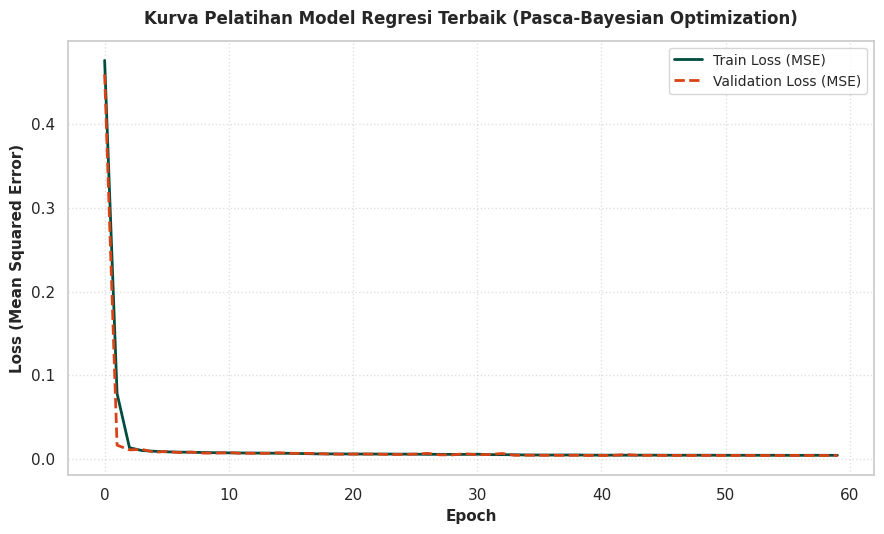

2026-10-30 06:26:33,761 - INFO - Arsitektur Regressor disimpan: outputs_lstm_bayesian/models/regressor/model_architecture_reg.png


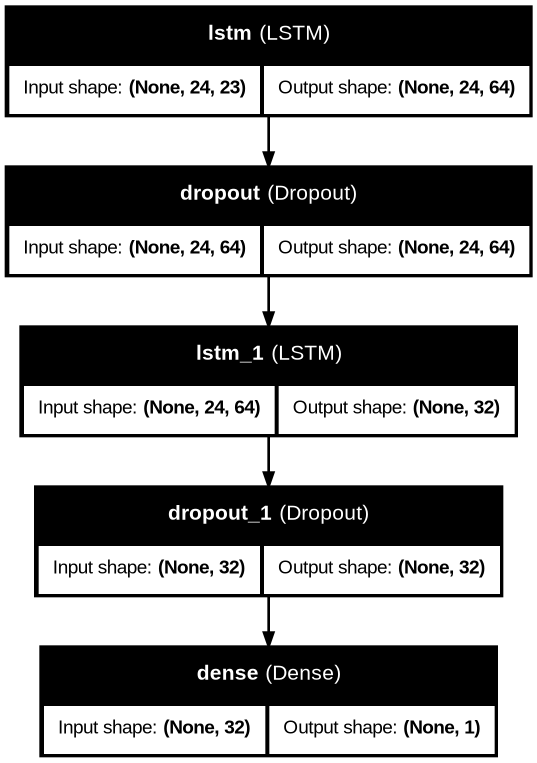

In [10]:
# Sel 8: Bayesian Optimization untuk Regressor LSTM
# TPE multivariate + HyperbandPruner + Search Space Diperluas + Regularisasi L2
import optuna
from optuna.pruners import HyperbandPruner
from tensorflow.keras.layers import LSTM, Dropout, Dense, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import gc
from tensorflow.keras import backend as K
import joblib

rainy_tr = y_tr_o == 1
rainy_va = y_va_o == 1

if np.sum(rainy_tr) > 10:
    X_tr_r_val, y_tr_r_val = X_tr_seq[rainy_tr], np.log1p(y_tr_r[rainy_tr])
    X_va_r_val, y_va_r_val = X_va_seq[rainy_va], np.log1p(y_va_r[rainy_va])

    def build_lstm_reg(lookback, units_l1, units_l2, lr, dropout):
        model = Sequential([
            Input(shape=(lookback, X.shape[1])),
            LSTM(units_l1, return_sequences=True),
            Dropout(dropout),
            LSTM(units_l2, return_sequences=False),
            Dropout(dropout),
            Dense(1, activation='relu')
        ])
        model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
        return model

    def objective_reg(trial):
        K.clear_session()
        gc.collect()
        units_l1     = trial.suggest_categorical('units_l1', SEARCH_UNITS_L1)
        units_l2     = trial.suggest_categorical('units_l2', SEARCH_UNITS_L2)
        lr           = trial.suggest_float('lr', SEARCH_LR_MIN, SEARCH_LR_MAX, log=True)
        dropout      = trial.suggest_categorical('dropout', SEARCH_DROPOUT)
        batch_size   = trial.suggest_categorical('batch_size', SEARCH_BATCH)
        
        model = build_lstm_reg(LOOKBACK, units_l1, units_l2, lr, dropout)
        es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
        pruning_cb = OptunaKerasPruningCallback(trial, monitor='val_loss')
        
        model.fit(
            X_tr_r_val, y_tr_r_val, 
            validation_data=(X_va_r_val, y_va_r_val),
            epochs=HYPERBAND_MAX_RESOURCE, 
            batch_size=batch_size, 
            callbacks=[es, pruning_cb], 
            verbose=0
        )
        val_loss = model.evaluate(X_va_r_val, y_va_r_val, verbose=0)
        return val_loss

    logger.info("Memulai Bayesian Optimization Optuna untuk LSTM Regressor (TPE Multivariate + Hyperband)...")
    db_path = evaluator.dirs['models'] / 'optuna_lstm_bayesian.db'
    storage_url = f"sqlite:///{db_path.as_posix()}"
    
    study_reg = optuna.create_study(
        study_name="lstm_regressor_bayesian",
        sampler=optuna.samplers.TPESampler(
            seed=SEED, 
            n_startup_trials=BAYESIAN_N_STARTUP_TRIALS,
            gamma=lambda n: min(int(np.ceil(BAYESIAN_GAMMA * n)), 25),
            multivariate=True, 
            warn_independent_sampling=False
        ),
        pruner=HyperbandPruner(
            min_resource=HYPERBAND_MIN_RESOURCE,
            max_resource=HYPERBAND_MAX_RESOURCE, 
            reduction_factor=HYPERBAND_REDUCTION_FACTOR
        ),
        storage=storage_url, 
        direction='minimize', 
        load_if_exists=True
    )
    study_reg.optimize(objective_reg, n_trials=OPTUNA_TRIALS)

    best_reg_params = study_reg.best_params
    logger.info(f"Parameter terbaik Regressor (Bayesian TPE): {best_reg_params}")

    # Ekspor riwayat trial regressor ke CSV
    df_trials_reg = study_reg.trials_dataframe()
    df_trials_reg.to_csv(evaluator.dirs['models_reg'] / 'optuna_trials_reg.csv', index=False)
    logger.info(f"Riwayat trial regressor disimpan ke: {evaluator.dirs['models_reg'] / 'optuna_trials_reg.csv'}")

    K.clear_session()
    gc.collect()

    reg_best = build_lstm_reg(
        LOOKBACK,
        best_reg_params['units_l1'],
        best_reg_params['units_l2'],
        best_reg_params['lr'],
        best_reg_params['dropout']
    )

    reg_ckpt_path = str(evaluator.dirs['models_reg'] / 'best_lstm_reg_ckpt.keras')
    es        = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
    ckpt_reg  = ModelCheckpoint(reg_ckpt_path, monitor='val_loss', save_best_only=True, verbose=0)

    history_reg = reg_best.fit(
        X_tr_r_val, y_tr_r_val,
        validation_data=(X_va_r_val, y_va_r_val),
        epochs=EPOCHS_BEST,
        batch_size=best_reg_params['batch_size'],
        callbacks=[es, reduce_lr, ckpt_reg],
        verbose=1
    )

    plt.figure(figsize=(9, 5.5))
    plt.plot(history_reg.history['loss'], label='Train Loss (MSE)', color='#004d40', linewidth=2.0)
    plt.plot(history_reg.history['val_loss'], label='Validation Loss (MSE)', color='#d84315', linewidth=2.0, linestyle='--')
    plt.title('Kurva Pelatihan Model Regresi Terbaik (Pasca-Bayesian Optimization)', fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('Epoch', fontsize=11, fontweight='bold')
    plt.ylabel('Loss (Mean Squared Error)', fontsize=11, fontweight='bold')
    plt.legend(loc='upper right', frameon=True, fontsize=10)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    p11_path = evaluator.dirs['plots'] / '11_training_loss_regressor.png'
    plt.savefig(p11_path, dpi=300, bbox_inches='tight')
    plt.savefig(evaluator.dirs['plots'] / 'training_loss_reg.png', dpi=300, bbox_inches='tight')
    logger.info(f'Plot training loss regressor disimpan: {p11_path}')
    plt.show()
    plt.close()

    reg_best.save(evaluator.dirs['models_reg'] / 'best_lstm_reg.keras')

    # Plot arsitektur model (Graphviz)
    try:
        from tensorflow.keras.utils import plot_model
        from IPython.display import Image, display
        _arch_path_reg = str(evaluator.dirs['models_reg'] / 'model_architecture_reg.png')
        plot_model(reg_best, to_file=_arch_path_reg, show_shapes=True, show_layer_names=True, dpi=96)
        logger.info(f"Arsitektur Regressor disimpan: {_arch_path_reg}")
        display(Image(_arch_path_reg))
    except Exception as _e:
        logger.warning(f"plot_model tidak tersedia (Graphviz belum terpasang): {_e}")
else:
    logger.warning("Tidak cukup sampel hujan untuk melatih regressor.")
    reg_best = None

### 6.1 Analisis Diagnostik & Visualisasi Tingkat Lanjut Bayesian Optimization — Regressor (BiLSTM)

Bagian ini menyajikan rangkaian analisis visual proses *Bayesian Optimization* untuk model regresi intensitas:

#### Visualisasi 1: Diagnostik Inti Regresi (4 Panel - `bayesian_diagnostics_reg.png`)
1. **Kurva Konvergensi (*MSE Minimization History*)**: Memperlihatkan laju penurunan galat kuadrat rerata (*Mean Squared Error*) sepanjang trial.
2. **Derajat Kepentingan Hiperparameter Regresi**: Mengidentifikasi parameter dominan dalam penentuan keakuratan besaran milimeter hujan.
3. **Lanskap Interaksi Kapasitas Layer**: Memetakan hubungan kapasitas layer 1 (`units_l1`) dan layer 2 (`units_l2`) terhadap MSE.
4. **Rasio Pemangkasan Hyperband**: Mengukur efisiensi pemangkasan arsitektur regresi yang mengalami divergensi gradien.

#### Visualisasi 2: Analisis Lanjutan TPE Parzen Kernel & Koordinat Paralel Regresi (`bayesian_advanced_tpe_analysis_reg.png`)
1. **Estimasi Densitas Kernel Parzen Regresi ($\ell(x)$ vs $g(x)$)**: Memperlihatkan pergeseran densitas parameter TPE menuju ruang dengan MSE terendah.
2. **Grafik Koordinat Paralel Regresi**: Memetakan konfigurasi parameter regresi yang menghasilkan MSE terbaik (*Top 20%*).
3. **Grafik *Marginal Slices* Regresi**: Memvisualisasikan sensitivitas MSE terhadap kapasitas unit dan ukuran *batch*.

2026-10-30 06:26:35,983 - INFO - Menghasilkan visualisasi diagnostik terpisah Bayesian Optimization untuk Regressor...
2026-10-30 06:26:36,489 - INFO - Plot diagnostik 12 disimpan: outputs_lstm_bayesian/plots/12_bayesian_reg_konvergensi_optimasi.png


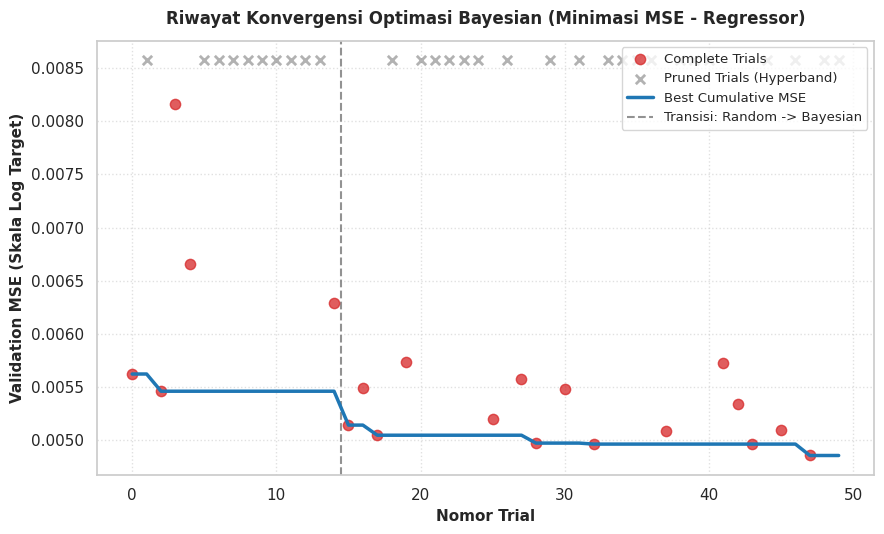

2026-10-30 06:26:37,033 - INFO - Plot diagnostik 13 disimpan: outputs_lstm_bayesian/plots/13_bayesian_reg_kepentingan_hiperparameter_fanova.png


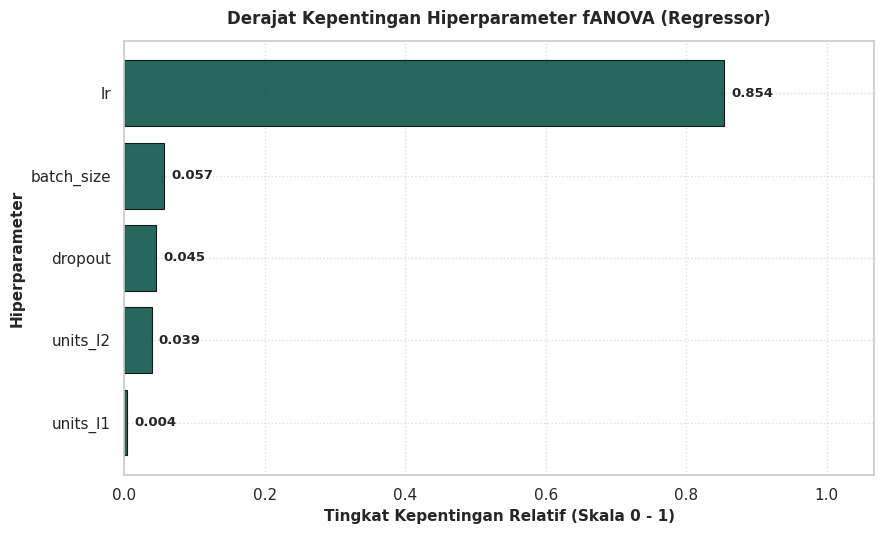

2026-10-30 06:26:37,675 - INFO - Plot diagnostik 14 disimpan: outputs_lstm_bayesian/plots/14_bayesian_reg_response_surface_units_l1_l2.png


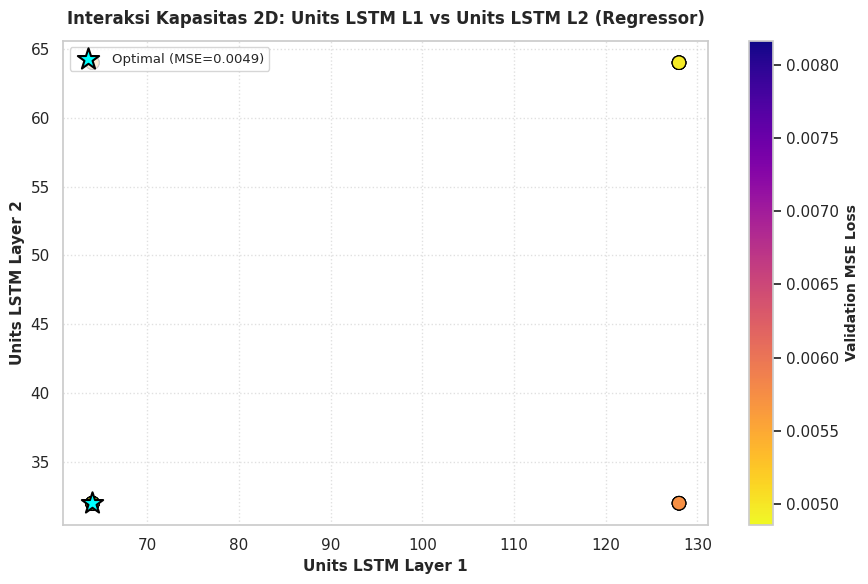

2026-10-30 06:26:38,155 - INFO - Plot diagnostik 15 disimpan: outputs_lstm_bayesian/plots/15_bayesian_reg_efisiensi_pruning_hyperband.png


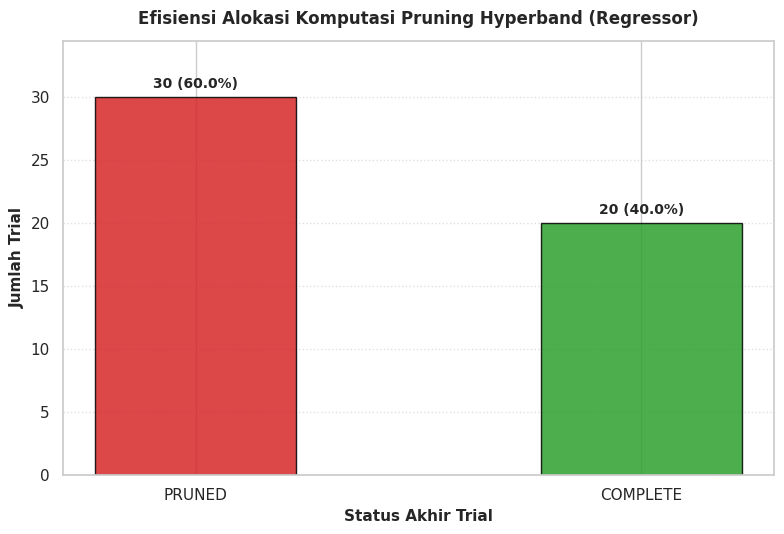

2026-10-30 06:26:38,826 - INFO - Plot diagnostik 16 disimpan: outputs_lstm_bayesian/plots/16_bayesian_reg_densitas_parzen_tpe_lr.png


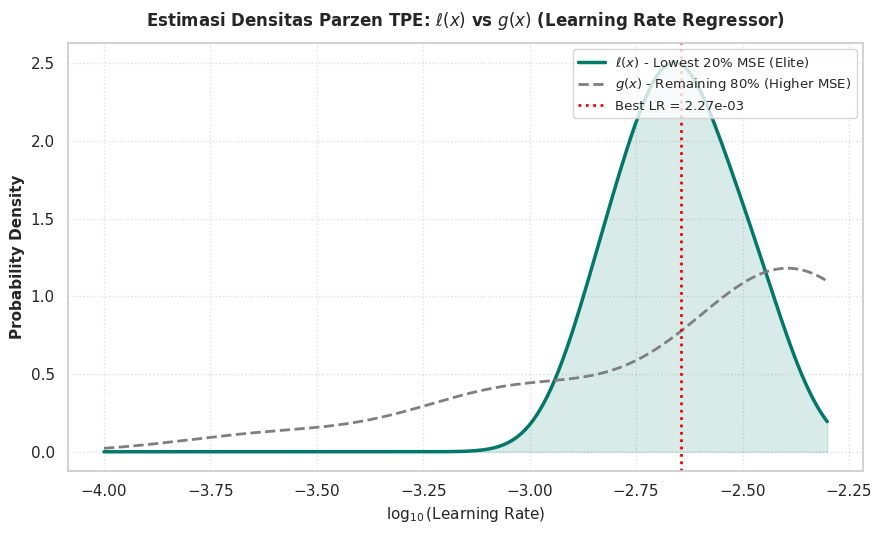

2026-10-30 06:26:39,574 - INFO - Plot diagnostik 17 disimpan: outputs_lstm_bayesian/plots/17_bayesian_reg_koordinat_paralel.png


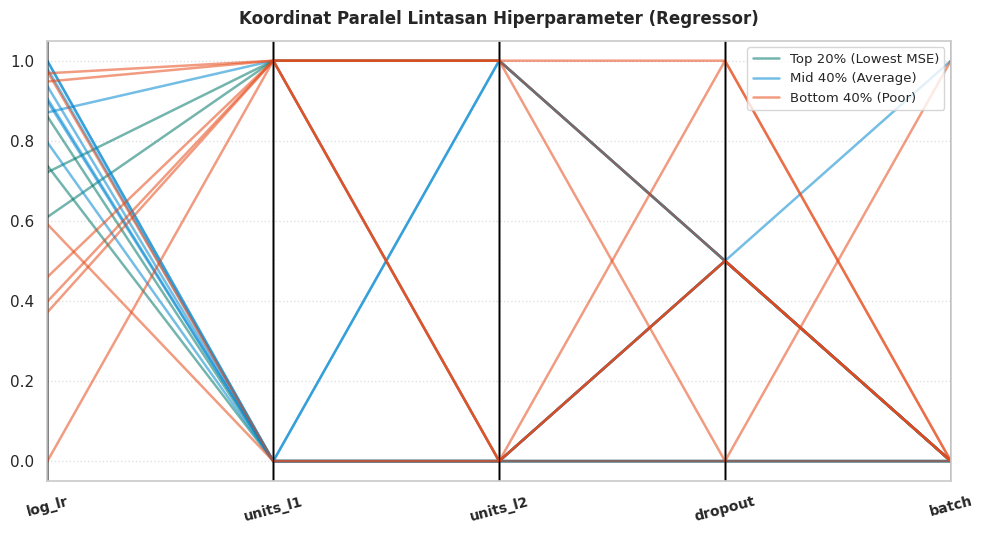

2026-10-30 06:26:40,148 - INFO - Plot diagnostik 18 disimpan: outputs_lstm_bayesian/plots/18_bayesian_reg_marginal_slice_units_l1.png


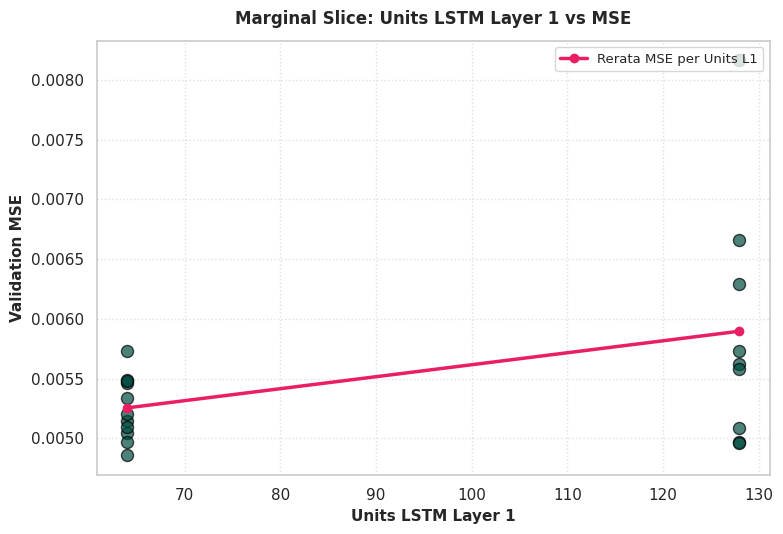

2026-10-30 06:26:40,679 - INFO - Plot diagnostik 19 disimpan: outputs_lstm_bayesian/plots/19_bayesian_reg_marginal_slice_batch_size.png


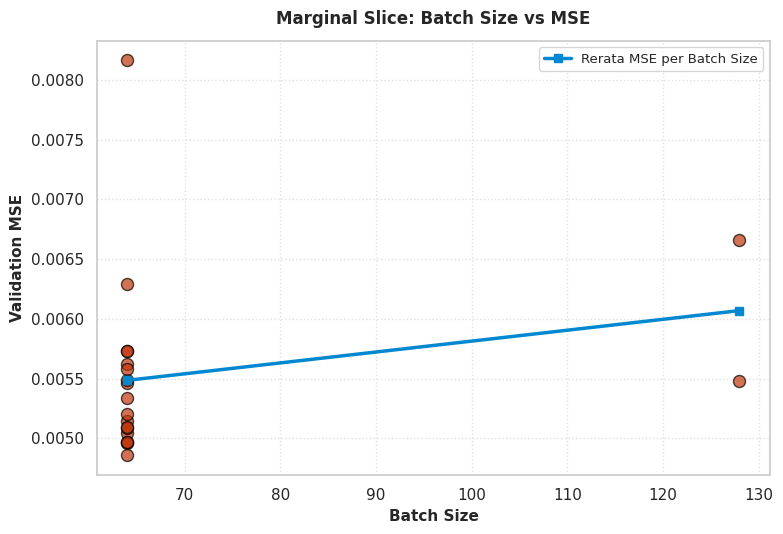

2026-10-30 06:26:40,807 - INFO - Seluruh 8 plot diagnostik terpisah Bayesian Regressor berhasil diekspor (300 DPI)!


In [11]:
# Sel 8.25: Visualisasi Diagnostik & Analisis Lanjutan Bayesian Optimization (Regressor)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import optuna
from scipy.stats import gaussian_kde
from pandas.plotting import parallel_coordinates

if reg_best is not None and 'study_reg' in locals():
    logger.info("Menghasilkan visualisasi diagnostik terpisah Bayesian Optimization untuk Regressor...")
    df_reg_trials = study_reg.trials_dataframe()
    df_reg_completed = df_reg_trials[df_reg_trials['state'] == 'COMPLETE'].copy()
    df_reg_pruned    = df_reg_trials[df_reg_trials['state'] == 'PRUNED'].copy()
    plot_dir_reg = evaluator.dirs['plots']
    plot_dir_reg.mkdir(parents=True, exist_ok=True)

    # ==============================================================================
    # PLOT 12: OPTIMIZATION HISTORY (MINIMIZING MSE - REGRESSOR)
    # ==============================================================================
    plt.figure(figsize=(9, 5.5))
    running_best_reg = []
    current_min = np.inf
    for v in df_reg_trials['value']:
        if pd.notna(v) and v < current_min:
            current_min = v
        running_best_reg.append(current_min if current_min != np.inf else np.nan)

    plt.scatter(df_reg_completed['number'], df_reg_completed['value'], color='#d62728', alpha=0.75, s=55, label='Complete Trials', zorder=3)
    if len(df_reg_pruned) > 0:
        max_val_r = df_reg_completed['value'].max() if len(df_reg_completed) > 0 else 1.0
        plt.scatter(df_reg_pruned['number'], [max_val_r * 1.05]*len(df_reg_pruned), 
                    color='#7f7f7f', marker='x', alpha=0.6, s=45, label='Pruned Trials (Hyperband)', zorder=2)
    plt.plot(df_reg_trials['number'], running_best_reg, color='#1f77b4', linewidth=2.5, label='Best Cumulative MSE', zorder=4)
    plt.axvline(x=BAYESIAN_N_STARTUP_TRIALS - 0.5, color='#7f7f7f', linestyle='--', linewidth=1.5, alpha=0.85,
                label=f'Transisi: Random -> Bayesian')
    plt.title('Riwayat Konvergensi Optimasi Bayesian (Minimasi MSE - Regressor)', fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('Nomor Trial', fontsize=11, fontweight='bold')
    plt.ylabel('Validation MSE (Skala Log Target)', fontsize=11, fontweight='bold')
    plt.legend(loc='upper right', frameon=True, fontsize=9.5)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    p12_path = plot_dir_reg / '12_bayesian_reg_konvergensi_optimasi.png'
    plt.savefig(p12_path, dpi=300, bbox_inches='tight')
    logger.info(f"Plot diagnostik 12 disimpan: {p12_path}")
    plt.show()
    plt.close()

    # ==============================================================================
    # PLOT 13: HYPERPARAMETER IMPORTANCES (fANOVA - REGRESSOR)
    # ==============================================================================
    plt.figure(figsize=(9, 5.5))
    try:
        param_imp_reg = optuna.importance.get_param_importances(study_reg)
        params_sorted_r = list(param_imp_reg.keys())[::-1]
        importances_sorted_r = [param_imp_reg[k] for k in params_sorted_r]
        bars2 = plt.barh(params_sorted_r, importances_sorted_r, color='#004d40', alpha=0.85, edgecolor='black', linewidth=0.8)
        plt.title('Derajat Kepentingan Hiperparameter fANOVA (Regressor)', fontsize=12, fontweight='bold', pad=12)
        plt.xlabel('Tingkat Kepentingan Relatif (Skala 0 - 1)', fontsize=11, fontweight='bold')
        plt.ylabel('Hiperparameter', fontsize=11, fontweight='bold')
        for bar in bars2:
            plt.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.3f}',
                     va='center', ha='left', fontsize=9.5, fontweight='bold')
        plt.xlim(0, max(importances_sorted_r) * 1.25 if importances_sorted_r else 1.0)
    except Exception as e:
        plt.text(0.5, 0.5, f"Evaluasi Importance Regressor: {e}", ha='center', va='center')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    p13_path = plot_dir_reg / '13_bayesian_reg_kepentingan_hiperparameter_fanova.png'
    plt.savefig(p13_path, dpi=300, bbox_inches='tight')
    logger.info(f"Plot diagnostik 13 disimpan: {p13_path}")
    plt.show()
    plt.close()

    # ==============================================================================
    # PLOT 14: 2D RESPONSE SURFACE (UNITS L1 VS UNITS L2 - REGRESSOR)
    # ==============================================================================
    plt.figure(figsize=(9, 6))
    if 'params_units_l1' in df_reg_completed.columns and 'params_units_l2' in df_reg_completed.columns:
        sc3 = plt.scatter(
            df_reg_completed['params_units_l1'],
            df_reg_completed['params_units_l2'],
            c=df_reg_completed['value'],
            cmap='plasma_r',
            s=95,
            edgecolors='black',
            linewidth=0.8,
            zorder=3
        )
        cbar3 = plt.colorbar(sc3)
        cbar3.set_label('Validation MSE Loss', fontsize=10, fontweight='bold')
        best_r = study_reg.best_trial
        plt.scatter(
            best_r.params['units_l1'], best_r.params['units_l2'],
            color='cyan', marker='*', s=260, edgecolor='black', linewidth=1.5,
            label=f'Optimal (MSE={study_reg.best_value:.4f})', zorder=5
        )
        plt.title('Interaksi Kapasitas 2D: Units LSTM L1 vs Units LSTM L2 (Regressor)', fontsize=12, fontweight='bold', pad=12)
        plt.xlabel('Units LSTM Layer 1', fontsize=11, fontweight='bold')
        plt.ylabel('Units LSTM Layer 2', fontsize=11, fontweight='bold')
        plt.legend(loc='upper left', frameon=True, fontsize=9.5)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    p14_path = plot_dir_reg / '14_bayesian_reg_response_surface_units_l1_l2.png'
    plt.savefig(p14_path, dpi=300, bbox_inches='tight')
    logger.info(f"Plot diagnostik 14 disimpan: {p14_path}")
    plt.show()
    plt.close()

    # ==============================================================================
    # PLOT 15: HYPERBAND PRUNING DISTRIBUTION (REGRESSOR)
    # ==============================================================================
    plt.figure(figsize=(8, 5.5))
    state_counts_r = df_reg_trials['state'].value_counts()
    colors_r = ['#2ca02c' if s == 'COMPLETE' else '#d62728' for s in state_counts_r.index]
    bars_r4 = plt.bar(state_counts_r.index, state_counts_r.values, color=colors_r, alpha=0.85, edgecolor='black', linewidth=1.0, width=0.45)
    plt.title('Efisiensi Alokasi Komputasi Pruning Hyperband (Regressor)', fontsize=12, fontweight='bold', pad=12)
    plt.ylabel('Jumlah Trial', fontsize=11, fontweight='bold')
    plt.xlabel('Status Akhir Trial', fontsize=11, fontweight='bold')
    for bar in bars_r4:
        height = bar.get_height()
        pct = (height / len(df_reg_trials)) * 100
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.5, f'{height} ({pct:.1f}%)',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.ylim(0, max(state_counts_r.values) * 1.15)
    plt.grid(True, axis='y', linestyle=':', alpha=0.6)
    plt.tight_layout()
    p15_path = plot_dir_reg / '15_bayesian_reg_efisiensi_pruning_hyperband.png'
    plt.savefig(p15_path, dpi=300, bbox_inches='tight')
    logger.info(f"Plot diagnostik 15 disimpan: {p15_path}")
    plt.show()
    plt.close()

    # ==============================================================================
    # PLOT 16: TPE PARZEN KERNEL DENSITY ESTIMATION: l(x) vs g(x) (REGRESSOR)
    # ==============================================================================
    plt.figure(figsize=(9, 5.5))
    if len(df_reg_completed) >= 5 and 'params_lr' in df_reg_completed.columns:
        q20_r = df_reg_completed['value'].quantile(0.20) # Lower is better for MSE
        top_trials_r = df_reg_completed[df_reg_completed['value'] <= q20_r]
        rest_trials_r = df_reg_completed[df_reg_completed['value'] > q20_r]
        
        log_lr_top_r = np.log10(top_trials_r['params_lr'])
        log_lr_rest_r = np.log10(rest_trials_r['params_lr'])
        x_grid_r = np.linspace(np.log10(SEARCH_LR_MIN), np.log10(SEARCH_LR_MAX), 200)
        try:
            kde_top_r = gaussian_kde(log_lr_top_r)
            kde_rest_r = gaussian_kde(log_lr_rest_r)
            dens_top_r = kde_top_r(x_grid_r)
            dens_rest_r = kde_rest_r(x_grid_r)
            
            plt.plot(x_grid_r, dens_top_r, label=r'$\ell(x)$ - Lowest 20% MSE (Elite)', color='#00796b', lw=2.5)
            plt.fill_between(x_grid_r, 0, dens_top_r, color='#00796b', alpha=0.15)
            plt.plot(x_grid_r, dens_rest_r, label=r'$g(x)$ - Remaining 80% (Higher MSE)', color='#7f7f7f', linestyle='--', lw=2.0)
            plt.axvline(x=np.log10(study_reg.best_params['lr']), color='red', linestyle=':', lw=2,
                        label=f"Best LR = {study_reg.best_params['lr']:.2e}")
            plt.title(r'Estimasi Densitas Parzen TPE: $\ell(x)$ vs $g(x)$ (Learning Rate Regressor)', fontsize=12, fontweight='bold', pad=12)
            plt.xlabel(r'$\log_{10}(\text{Learning Rate})$', fontsize=11, fontweight='bold')
            plt.ylabel('Probability Density', fontsize=11, fontweight='bold')
            plt.legend(loc='upper right', frameon=True, fontsize=9.5)
        except Exception as _e_kde_r:
            plt.text(0.5, 0.5, f"KDE Regressor: {_e_kde_r}", ha='center', va='center')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    p16_path = plot_dir_reg / '16_bayesian_reg_densitas_parzen_tpe_lr.png'
    plt.savefig(p16_path, dpi=300, bbox_inches='tight')
    logger.info(f"Plot diagnostik 16 disimpan: {p16_path}")
    plt.show()
    plt.close()

    # ==============================================================================
    # PLOT 17: PARALLEL COORDINATES PLOT (REGRESSOR)
    # ==============================================================================
    plt.figure(figsize=(10, 5.5))
    if len(df_reg_completed) >= 3:
        norm_df_r = pd.DataFrame()
        norm_df_r['log_lr'] = np.log10(df_reg_completed['params_lr'])
        norm_df_r['units_l1'] = df_reg_completed['params_units_l1']
        norm_df_r['units_l2'] = df_reg_completed['params_units_l2']
        norm_df_r['dropout'] = df_reg_completed['params_dropout']
        norm_df_r['batch'] = df_reg_completed['params_batch_size']
        if 'params_weight_decay' in df_reg_completed.columns:
            norm_df_r['log_wd'] = np.log10(df_reg_completed['params_weight_decay'])

        q_top_r = df_reg_completed['value'].quantile(0.20) # Lower is better
        q_mid_r = df_reg_completed['value'].quantile(0.60)
        def assign_tier_r(val):
            if val <= q_top_r: return 'Top 20% (Lowest MSE)'
            elif val <= q_mid_r: return 'Mid 40% (Average)'
            else: return 'Bottom 40% (Poor)'
        norm_df_r['Tier'] = df_reg_completed['value'].apply(assign_tier_r)

        feat_cols_r = [c for c in norm_df_r.columns if c != 'Tier']
        for col in feat_cols_r:
            cmin, cmax = norm_df_r[col].min(), norm_df_r[col].max()
            norm_df_r[col] = (norm_df_r[col] - cmin) / (cmax - cmin + 1e-9)

        color_map_r = {'Top 20% (Lowest MSE)': '#00796b', 'Mid 40% (Average)': '#0288d1', 'Bottom 40% (Poor)': '#e64a19'}
        for tier, col in color_map_r.items():
            sub = norm_df_r[norm_df_r['Tier'] == tier]
            if len(sub) > 0:
                parallel_coordinates(sub, 'Tier', color=[col], alpha=0.55, linewidth=1.8)
        plt.title('Koordinat Paralel Lintasan Hiperparameter (Regressor)', fontsize=12, fontweight='bold', pad=12)
        plt.legend(loc='upper right', frameon=True, fontsize=9.5)
        plt.xticks(rotation=15, fontsize=10, fontweight='bold')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    p17_path = plot_dir_reg / '17_bayesian_reg_koordinat_paralel.png'
    plt.savefig(p17_path, dpi=300, bbox_inches='tight')
    logger.info(f"Plot diagnostik 17 disimpan: {p17_path}")
    plt.show()
    plt.close()

    # ==============================================================================
    # PLOT 18: MARGINAL SLICE: UNITS LSTM LAYER 1 VS MSE (REGRESSOR)
    # ==============================================================================
    plt.figure(figsize=(8, 5.5))
    if 'params_units_l1' in df_reg_completed.columns:
        plt.scatter(df_reg_completed['params_units_l1'], df_reg_completed['value'], color='#004d40', s=75, alpha=0.7, edgecolors='black')
        means_l1_r = df_reg_completed.groupby('params_units_l1')['value'].mean()
        plt.plot(means_l1_r.index, means_l1_r.values, color='#e91e63', marker='o', lw=2.5, label='Rerata MSE per Units L1')
        plt.title('Marginal Slice: Units LSTM Layer 1 vs MSE', fontsize=12, fontweight='bold', pad=12)
        plt.xlabel('Units LSTM Layer 1', fontsize=11, fontweight='bold')
        plt.ylabel('Validation MSE', fontsize=11, fontweight='bold')
        plt.legend(loc='upper right', frameon=True, fontsize=9.5)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    p18_path = plot_dir_reg / '18_bayesian_reg_marginal_slice_units_l1.png'
    plt.savefig(p18_path, dpi=300, bbox_inches='tight')
    logger.info(f"Plot diagnostik 18 disimpan: {p18_path}")
    plt.show()
    plt.close()

    # ==============================================================================
    # PLOT 19: MARGINAL SLICE: BATCH SIZE VS MSE (REGRESSOR)
    # ==============================================================================
    plt.figure(figsize=(8, 5.5))
    if 'params_batch_size' in df_reg_completed.columns:
        plt.scatter(df_reg_completed['params_batch_size'], df_reg_completed['value'], color='#bf360c', s=75, alpha=0.7, edgecolors='black')
        means_bs_r = df_reg_completed.groupby('params_batch_size')['value'].mean()
        plt.plot(means_bs_r.index, means_bs_r.values, color='#0288d1', marker='s', lw=2.5, label='Rerata MSE per Batch Size')
        plt.title('Marginal Slice: Batch Size vs MSE', fontsize=12, fontweight='bold', pad=12)
        plt.xlabel('Batch Size', fontsize=11, fontweight='bold')
        plt.ylabel('Validation MSE', fontsize=11, fontweight='bold')
        plt.legend(loc='upper right', frameon=True, fontsize=9.5)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    p19_path = plot_dir_reg / '19_bayesian_reg_marginal_slice_batch_size.png'
    plt.savefig(p19_path, dpi=300, bbox_inches='tight')
    logger.info(f"Plot diagnostik 19 disimpan: {p19_path}")
    plt.show()
    plt.close()

    logger.info("Seluruh 8 plot diagnostik terpisah Bayesian Regressor berhasil diekspor (300 DPI)!")
else:
    logger.info("Visualisasi diagnostik regressor dilewati (model regresi tidak aktif).")


### 6.2 Evaluasi Komparatif Eksplorasi Acak vs Eksploitasi Bayesian & Ringkasan Konfigurasi Optimal

Tabel berikut menganalisis secara kuantitatif efektivitas algoritma **Bayesian Optimization (TPE Multivariate)** dibandingkan dengan **Eksplorasi Acak Murni (*Random Exploration*)** yang terjadi pada 15 trial inisial (*startup trials*), serta merangkum konfigurasi hiperparameter optimal yang ditemukan untuk kedua model.

In [12]:
# Sel 8.5: Evaluasi Komparatif & Ringkasan Konfigurasi Optimal Bayesian
import pandas as pd
import numpy as np

logger.info("Menghitung metrik perbandingan eksplorasi acak vs eksploitasi Bayesian...")

# 1. ANALISIS KOMPARATIF: Random Startup vs Bayesian Exploitation
def analyze_phase_comparison(study, metric_name, higher_is_better=True):
    df = study.trials_dataframe()
    df_comp = df[df['state'] == 'COMPLETE'].copy()
    
    # Pisahkan fase acak vs fase bayesian
    random_phase   = df_comp[df_comp['number'] < BAYESIAN_N_STARTUP_TRIALS]
    bayesian_phase = df_comp[df_comp['number'] >= BAYESIAN_N_STARTUP_TRIALS]
    
    all_random   = df[df['number'] < BAYESIAN_N_STARTUP_TRIALS]
    all_bayesian = df[df['number'] >= BAYESIAN_N_STARTUP_TRIALS]
    
    prune_rate_rand = (all_random['state'] == 'PRUNED').mean() * 100 if len(all_random) > 0 else 0.0
    prune_rate_bayes = (all_bayesian['state'] == 'PRUNED').mean() * 100 if len(all_bayesian) > 0 else 0.0
    
    best_rand = random_phase['value'].max() if higher_is_better else random_phase['value'].min()
    best_bayes = bayesian_phase['value'].max() if higher_is_better else bayesian_phase['value'].min()
    
    mean_rand = random_phase['value'].mean()
    mean_bayes = bayesian_phase['value'].mean()
    
    std_rand = random_phase['value'].std()
    std_bayes = bayesian_phase['value'].std()
    
    # Estimasi penghematan waktu GPU berkat pruning Hyperband
    total_max_epochs = len(df) * HYPERBAND_MAX_RESOURCE
    # Perkiraan epoch riil: pruned diasumsikan terhenti di rata-rata min_resource
    epochs_used = (df['state'] == 'COMPLETE').sum() * HYPERBAND_MAX_RESOURCE + (df['state'] == 'PRUNED').sum() * HYPERBAND_MIN_RESOURCE
    gpu_savings_pct = (1.0 - (epochs_used / total_max_epochs)) * 100
    
    return {
        'Metrik': metric_name,
        'Best (Fase Acak 1-15)': f"{best_rand:.4f}",
        'Best (Fase Bayesian 16-50)': f"{best_bayes:.4f}",
        'Peningkatan Skor': f"{abs(best_bayes - best_rand):.4f} ({'+' if (best_bayes > best_rand and higher_is_better) or (best_bayes < best_rand and not higher_is_better) else '-'}{abs(best_bayes - best_rand)/abs(best_rand)*100:.1f}%)",
        'Rerata Skor (Acak)': f"{mean_rand:.4f} ± {std_rand:.3f}",
        'Rerata Skor (Bayesian)': f"{mean_bayes:.4f} ± {std_bayes:.3f}",
        'Tingkat Pruning (Hyperband)': f"{prune_rate_bayes:.1f}%",
        'Estimasi Efisiensi GPU': f"{gpu_savings_pct:.1f}% waktu tersimpan"
    }

comp_records = []
if 'study_clf' in locals():
    comp_records.append(analyze_phase_comparison(study_clf, "Classifier (F1-Score)", higher_is_better=True))
if 'study_reg' in locals() and reg_best is not None:
    comp_records.append(analyze_phase_comparison(study_reg, "Regressor (MSE Loss)", higher_is_better=False))

df_hpo_comp = pd.DataFrame(comp_records)
print("=== TABEL 1: PERBANDINGAN KINERJA FASE RANDOM STARTUP VS EKSPLOITASI BAYESIAN ===")
display(df_hpo_comp)
df_hpo_comp.to_csv(evaluator.dirs['models'] / 'hpo_phase_comparison.csv', index=False)

# 2. RINGKASAN KONFIGURASI OPTIMAL & RASIONALISASI FISIKA ATMOSFER
clf_opt = study_clf.best_params if 'study_clf' in locals() else {}
reg_opt = study_reg.best_params if ('study_reg' in locals() and reg_best is not None) else {}

summary_rows = [
    {
        'Hiperparameter': 'Units Layer 1 (units_l1)',
        'Ruang Pencarian (Search Space)': str(SEARCH_UNITS_L1),
        'Optimal Classifier': clf_opt.get('units_l1', '-'),
        'Optimal Regressor': reg_opt.get('units_l1', '-'),
        'Rasionalisasi Fisika & Komputasi': 'Ekstraksi fitur non-linier sekuensial dari 14 variabel termodinamika atmosfer.'
    },
    {
        'Hiperparameter': 'Units Layer 2 (units_l2)',
        'Ruang Pencarian (Search Space)': str(SEARCH_UNITS_L2),
        'Optimal Classifier': clf_opt.get('units_l2', '-'),
        'Optimal Regressor': reg_opt.get('units_l2', '-'),
        'Rasionalisasi Fisika & Komputasi': 'Kompresi representasi temporal sebelum proyeksi ke probabilitas/kuantitas presipitasi.'
    },
    {
        'Hiperparameter': 'Laju Pembelajaran (lr)',
        'Ruang Pencarian (Search Space)': f"[{SEARCH_LR_MIN:.1e}, {SEARCH_LR_MAX:.1e}] (Log)",
        'Optimal Classifier': f"{clf_opt.get('lr', 0):.2e}" if 'lr' in clf_opt else '-',
        'Optimal Regressor': f"{reg_opt.get('lr', 0):.2e}" if 'lr' in reg_opt else '-',
        'Rasionalisasi Fisika & Komputasi': 'Konvergensi stabil optimizer Adam tanpa fluktuasi gradien tajam pada time-series panjang.'
    },
    {
        'Hiperparameter': 'Tingkat Dropout (dropout)',
        'Ruang Pencarian (Search Space)': str(SEARCH_DROPOUT),
        'Optimal Classifier': clf_opt.get('dropout', '-'),
        'Optimal Regressor': reg_opt.get('dropout', '-'),
        'Rasionalisasi Fisika & Komputasi': 'Regularisasi stokhastik untuk memecah ko-adaptasi antar sel LSTM pada kondisi cuaca ekstrem.'
    },
    {
        'Hiperparameter': 'Ukuran Batch (batch_size)',
        'Ruang Pencarian (Search Space)': str(SEARCH_BATCH),
        'Optimal Classifier': clf_opt.get('batch_size', '-'),
        'Optimal Regressor': reg_opt.get('batch_size', '-'),
        'Rasionalisasi Fisika & Komputasi': 'Menyeimbangkan aproksimasi gradien mini-batch dan efisiensi throughput VRAM GPU.'
    },
    {
        'Hiperparameter': 'Classification Threshold (τ)',
        'Ruang Pencarian (Search Space)': '[0.20, 0.70] (step 0.02)',
        'Optimal Classifier': f"{study_clf.best_trial.user_attrs.get('best_threshold', 0.5):.2f}" if 'study_clf' in locals() else '-',
        'Optimal Regressor': 'N/A (Regresi Kontinu)',
        'Rasionalisasi Fisika & Komputasi': 'Ambang batas probabilitas optimal penyeimbang Presisi dan Recall pada data zero-inflated (>85% kering).'
    }
]

df_hpo_summary = pd.DataFrame(summary_rows)
print("\n=== TABEL 2: SPESIFIKASI KONFIGURASI OPTIMAL HASIL BAYESIAN OPTIMIZATION ===")
display(df_hpo_summary)
df_hpo_summary.to_csv(evaluator.dirs['models'] / 'hpo_best_configuration_summary.csv', index=False)
logger.info("Analisis komparatif dan ringkasan konfigurasi optimal berhasil disimpan.")

2026-10-30 06:26:42,930 - INFO - Menghitung metrik perbandingan eksplorasi acak vs eksploitasi Bayesian...


=== TABEL 1: PERBANDINGAN KINERJA FASE RANDOM STARTUP VS EKSPLOITASI BAYESIAN ===


,Metrik,Best (Fase Acak 1-15),Best (Fase Bayesian 16-50),Peningkatan Skor,Rerata Skor (Acak),Rerata Skor (Bayesian),Tingkat Pruning (Hyperband),Estimasi Efisiensi GPU
0,Classifier (F1-Score),0.9465,0.9456,0.0009 (-0.1%),0.9383 ± 0.013,0.9317 ± 0.011,60.0%,53.3% waktu tersimpan
1,Regressor (MSE Loss),0.0055,0.0049,0.0006 (+11.1%),0.0064 ± 0.001,0.0052 ± 0.000,57.1%,50.0% waktu tersimpan



=== TABEL 2: SPESIFIKASI KONFIGURASI OPTIMAL HASIL BAYESIAN OPTIMIZATION ===


,Hiperparameter,Ruang Pencarian (Search Space),Optimal Classifier,Optimal Regressor,Rasionalisasi Fisika & Komputasi
0,Units Layer 1 (units_l1),"[64, 128]",128,64,Ekstraksi fitur non-linier sekuensial dari 14 ...
1,Units Layer 2 (units_l2),"[32, 64]",32,32,Kompresi representasi temporal sebelum proyeks...
2,Laju Pembelajaran (lr),"[1.0e-04, 5.0e-03] (Log)",7.61e-04,2.27e-03,Konvergensi stabil optimizer Adam tanpa fluktu...
3,Tingkat Dropout (dropout),"[0.1, 0.2, 0.3]",0.1,0.1,Regularisasi stokhastik untuk memecah ko-adapt...
4,Ukuran Batch (batch_size),"[64, 128, 256]",64,64,Menyeimbangkan aproksimasi gradien mini-batch ...
5,Classification Threshold (τ),"[0.20, 0.70] (step 0.02)",0.48,N/A (Regresi Kontinu),Ambang batas probabilitas optimal penyeimbang ...


2026-10-30 06:26:42,984 - INFO - Analisis komparatif dan ringkasan konfigurasi optimal berhasil disimpan.


## Tahap 7: Evaluasi Terpadu Model Dua Tahap (*Two-Stage Hurdle LSTM*)

Bagian ini mengevaluasi kinerja menyeluruh arsitektur **Two-Stage Hurdle Model** pada data uji independen:
1. **Evaluasi Tahap 1 (Klasifikasi)**: Menguji deteksi kejadian hujan menggunakan metrik meteorologi standar (CSI, ETS, POD, FAR, HSS), akurasi probabilistik (Brier Score, ECE, MCE), dan matriks konfusi.
2. **Evaluasi Tahap 2 (Regresi Kondisional)**: Menguji akurasi estimasi kuantitas presipitasi pada saat hujan terjadi (RMSE, MAE, R², NSE, KGE).
3. **Evaluasi Terpadu (*End-to-End Joint Hurdle*)**: Menguji estimasi akhir di mana intensitas regresi hanya dialokasikan jika tahap klasifikasi memprediksi hujan.
4. **Visualisasi Profil Runtun Waktu (*Timeseries Profile*)**: Membandingkan deret waktu observasi aktual versus prediksi model dua tahap sepanjang 336 jam (14 hari).

2026-10-30 06:26:45,116 - INFO - Memulai Evaluasi Terpadu Model Dua Tahap (Two-Stage Hurdle LSTM)...
2026-10-30 06:26:45,371 - INFO - Threshold klasifikasi optimal: 0.48 (Metode Kalibrasi: Isotonic)
2026-10-30 06:26:48,134 - INFO - Menghitung metrik klasifikasi...


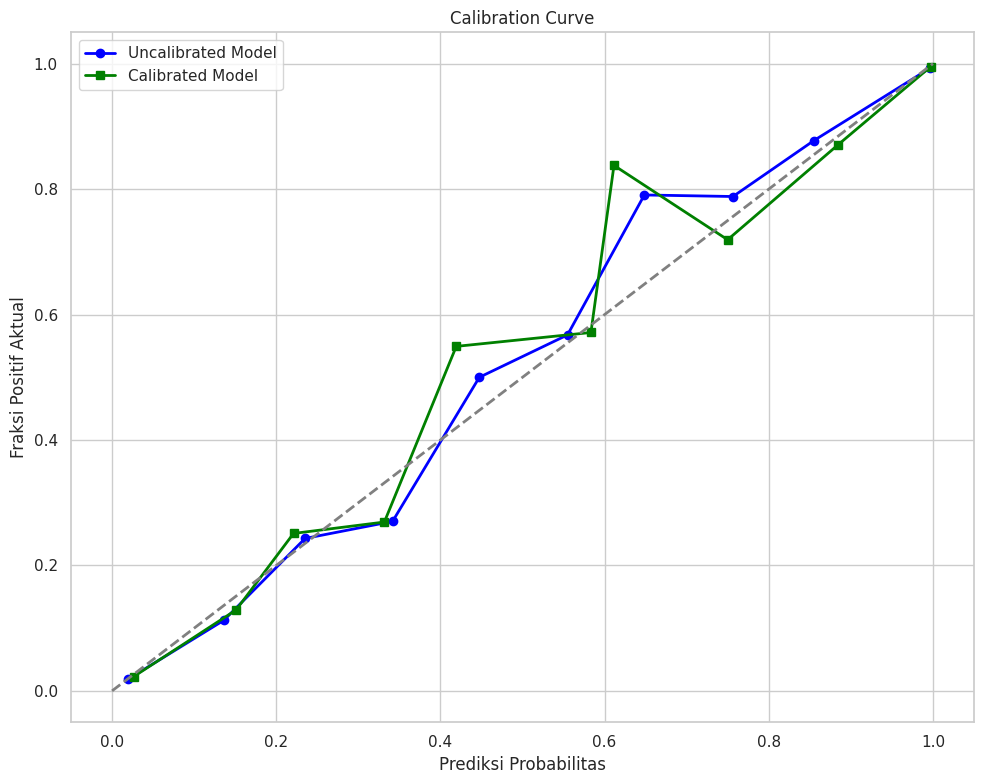

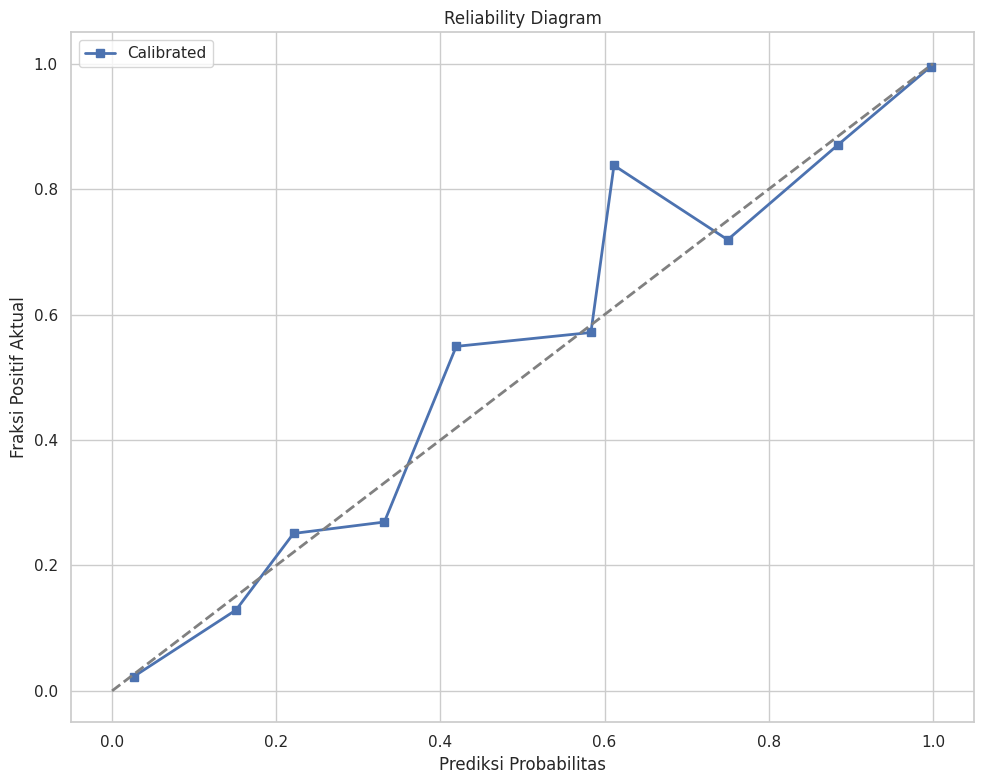

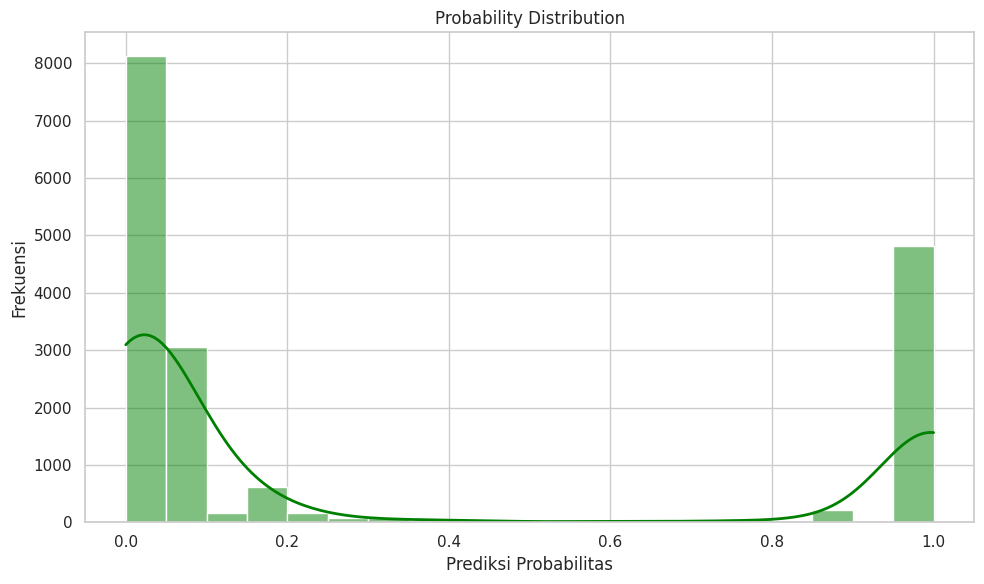

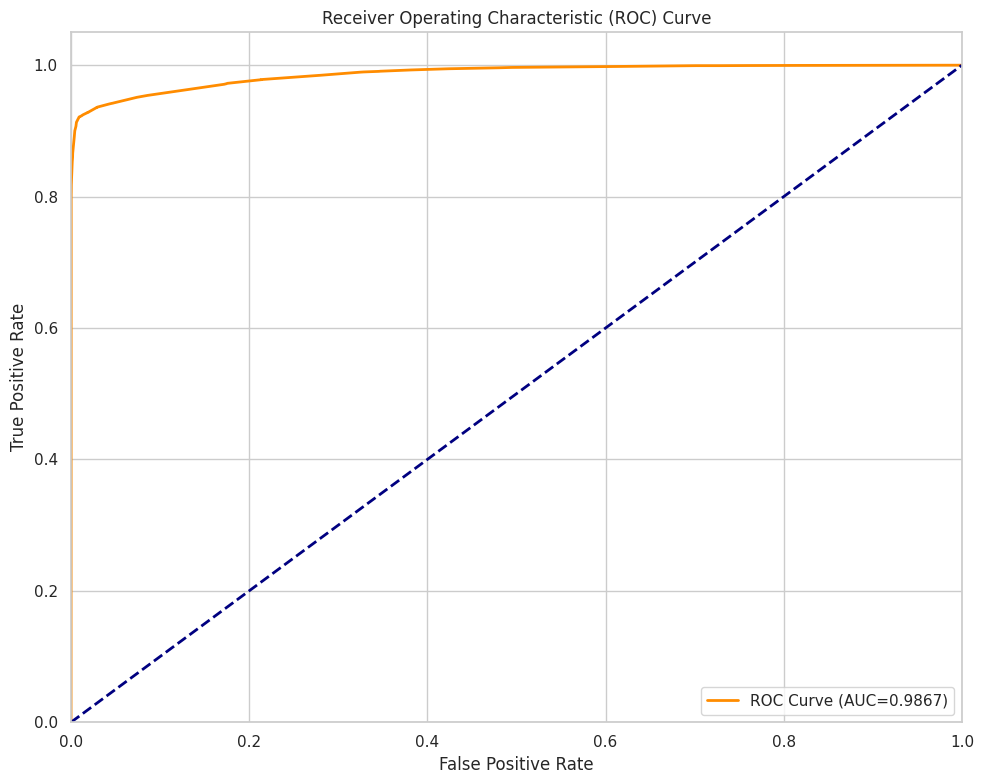

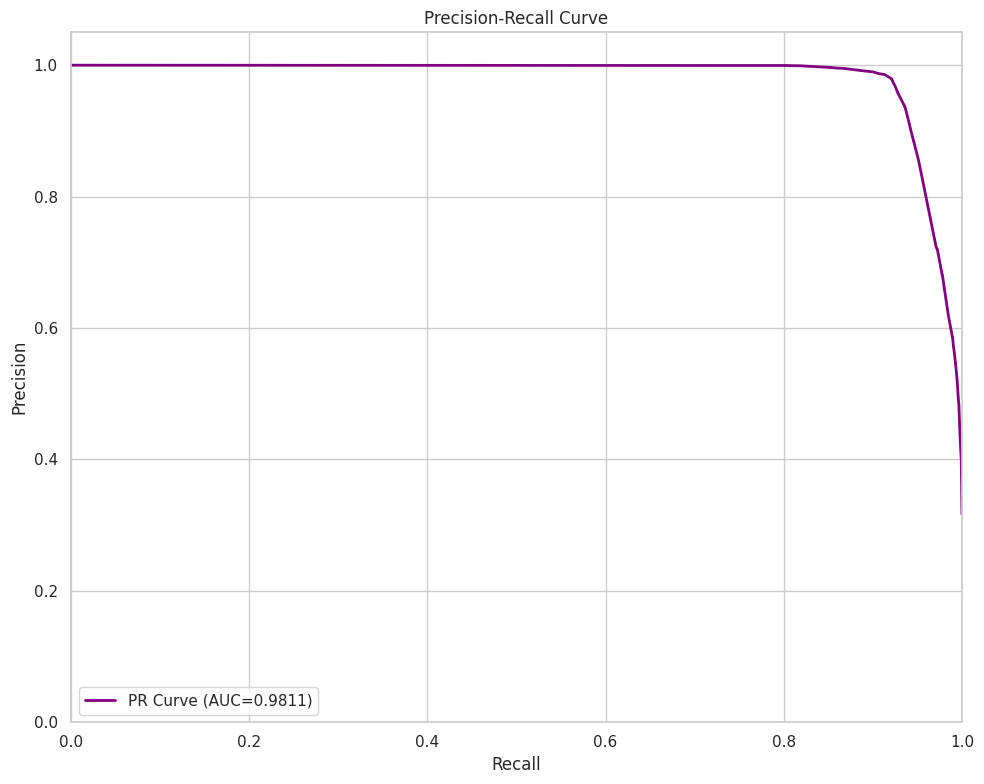

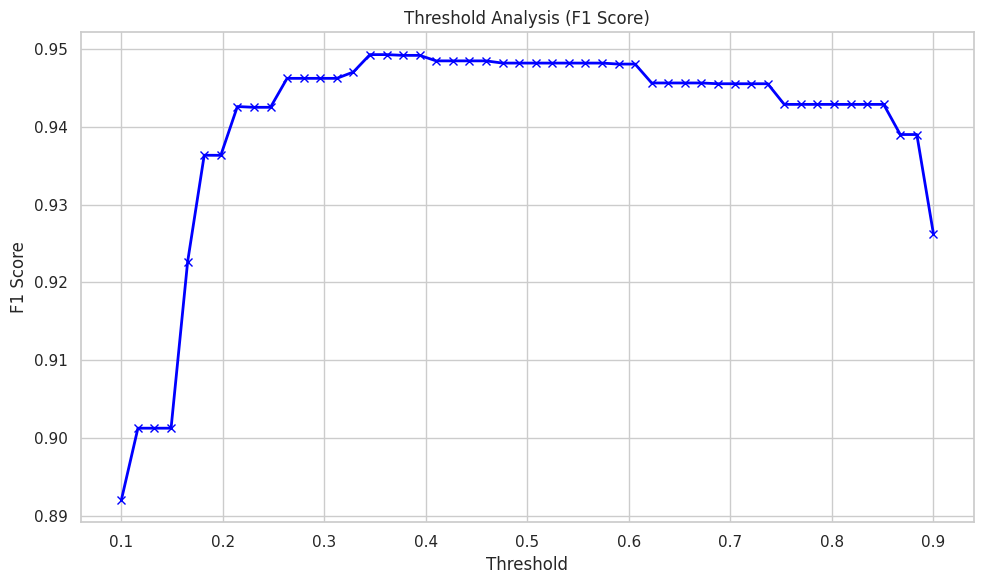

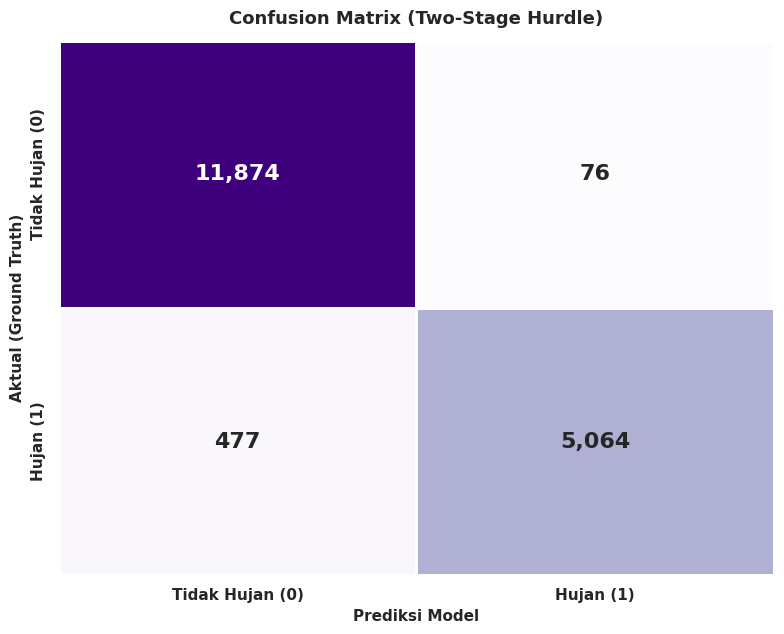

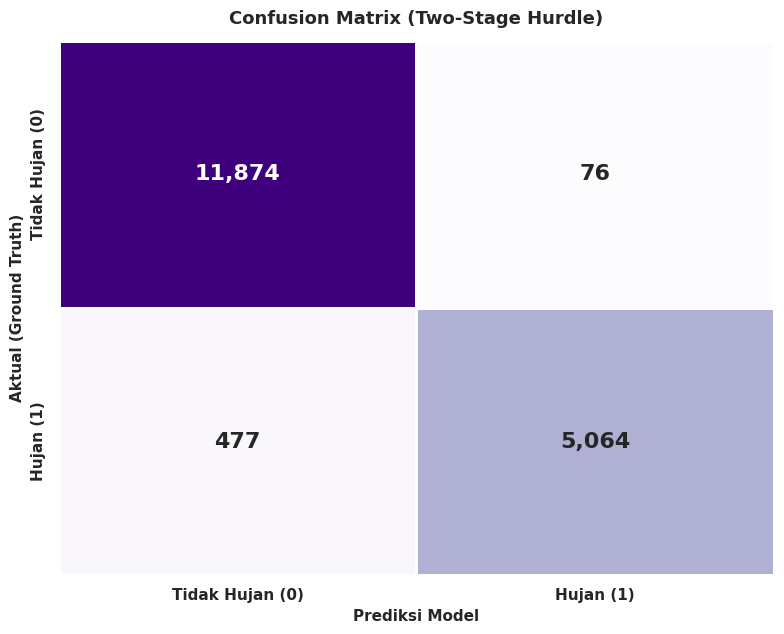

2026-10-30 06:26:54,033 - INFO - Menghitung metrik regresi...


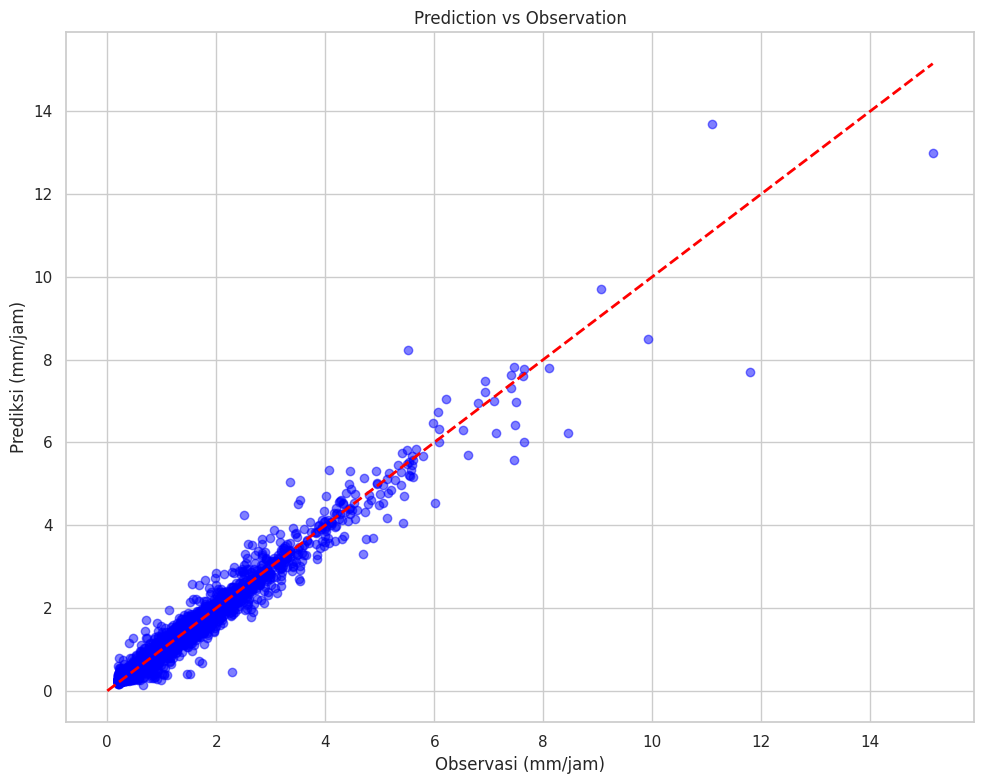

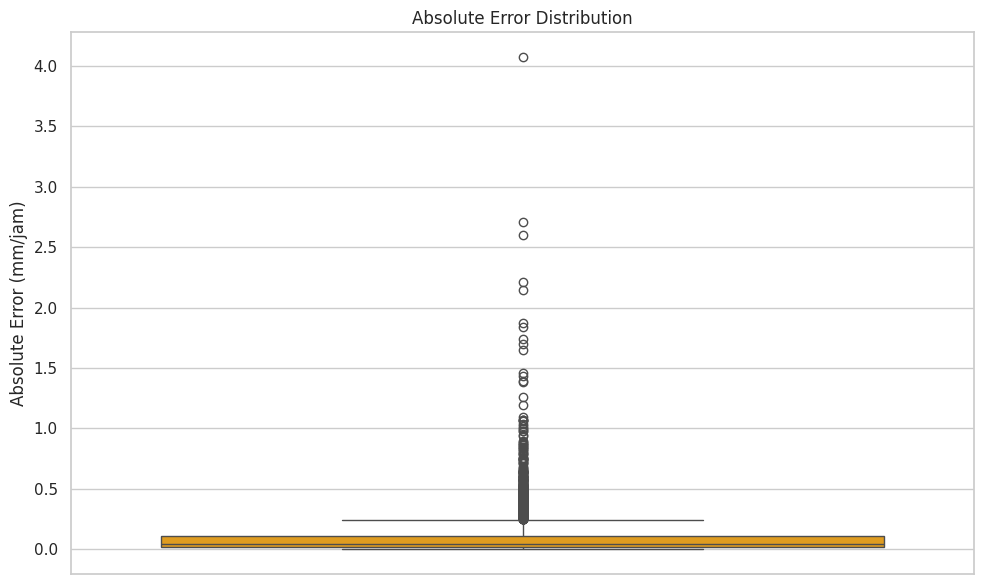

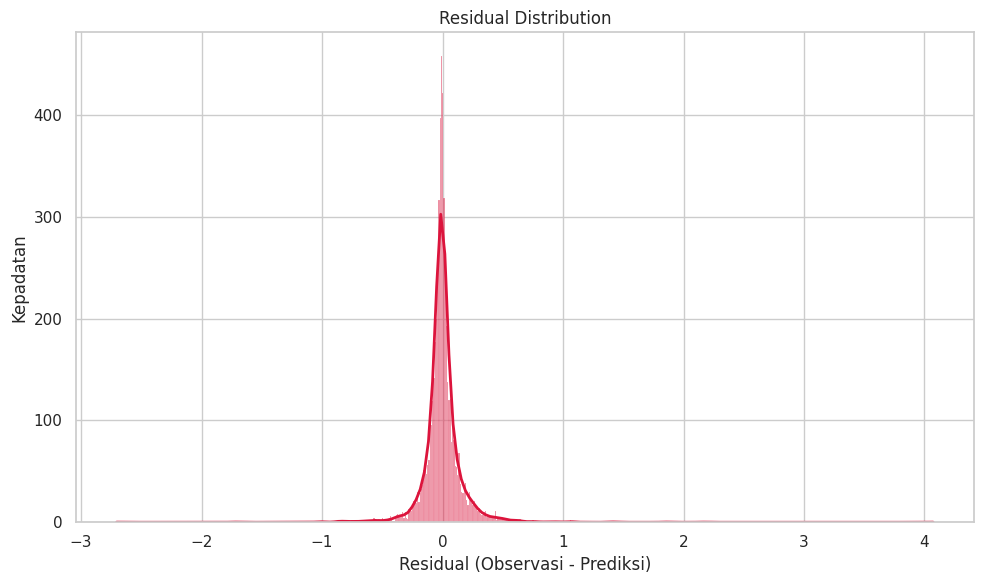

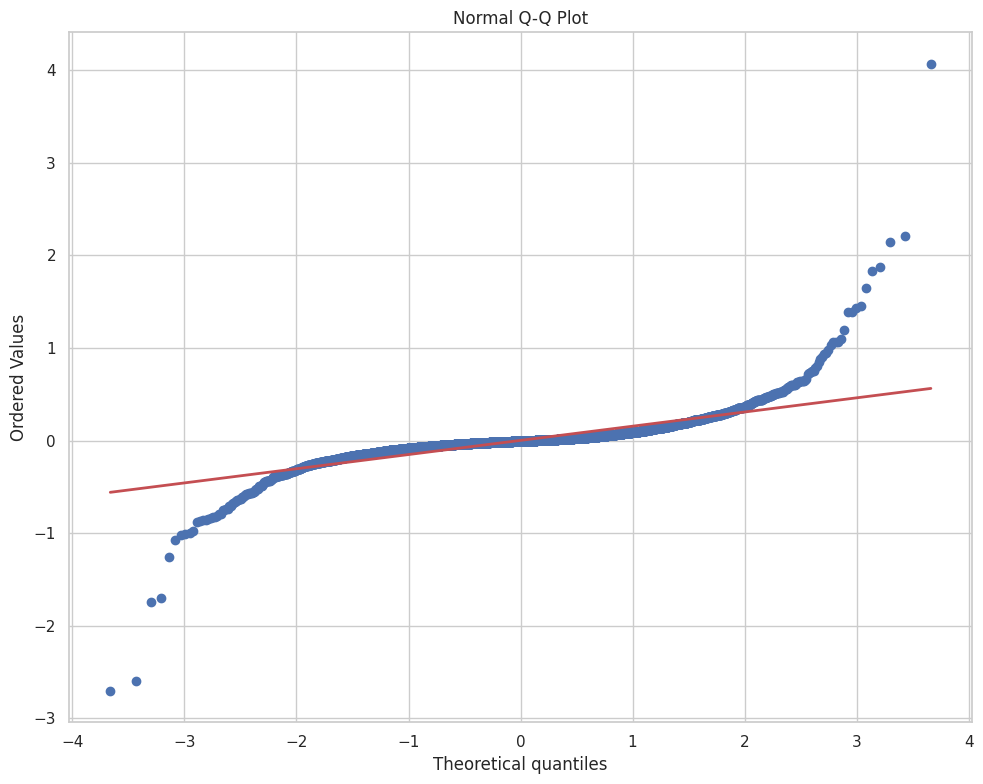

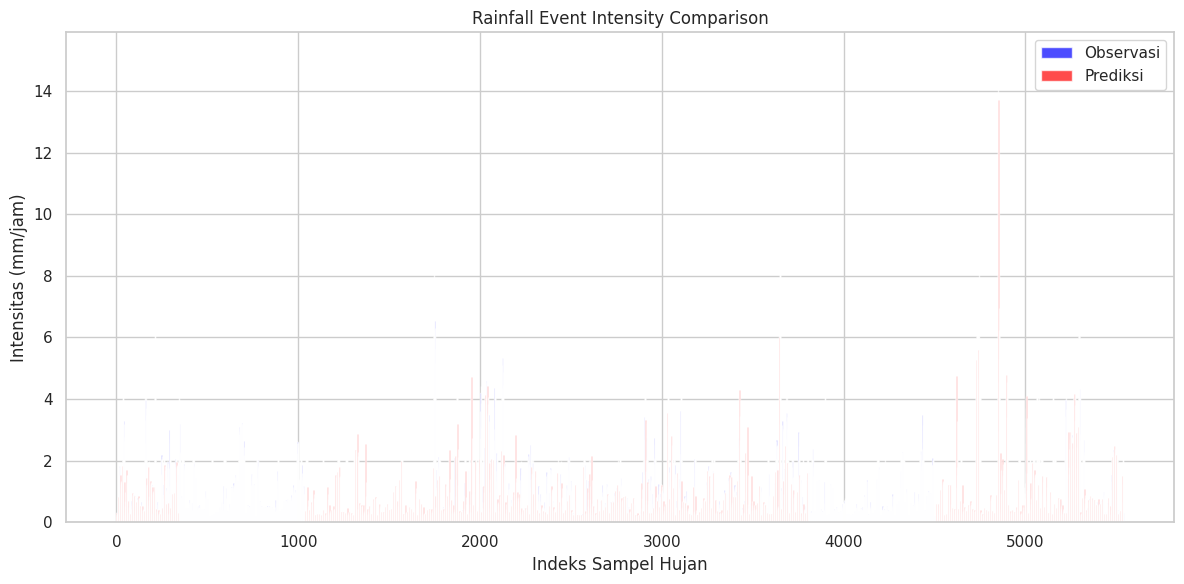

2026-10-30 06:27:20,910 - INFO - [Two-Stage End-to-End Hurdle] RMSE: 0.1204 mm, MAE: 0.0375 mm, R2: 0.9724
2026-10-30 06:27:22,398 - INFO - Plot runtun waktu prediksi dua tahap disimpan: outputs_lstm_bayesian/plots/21_two_stage_timeseries_prediction.png


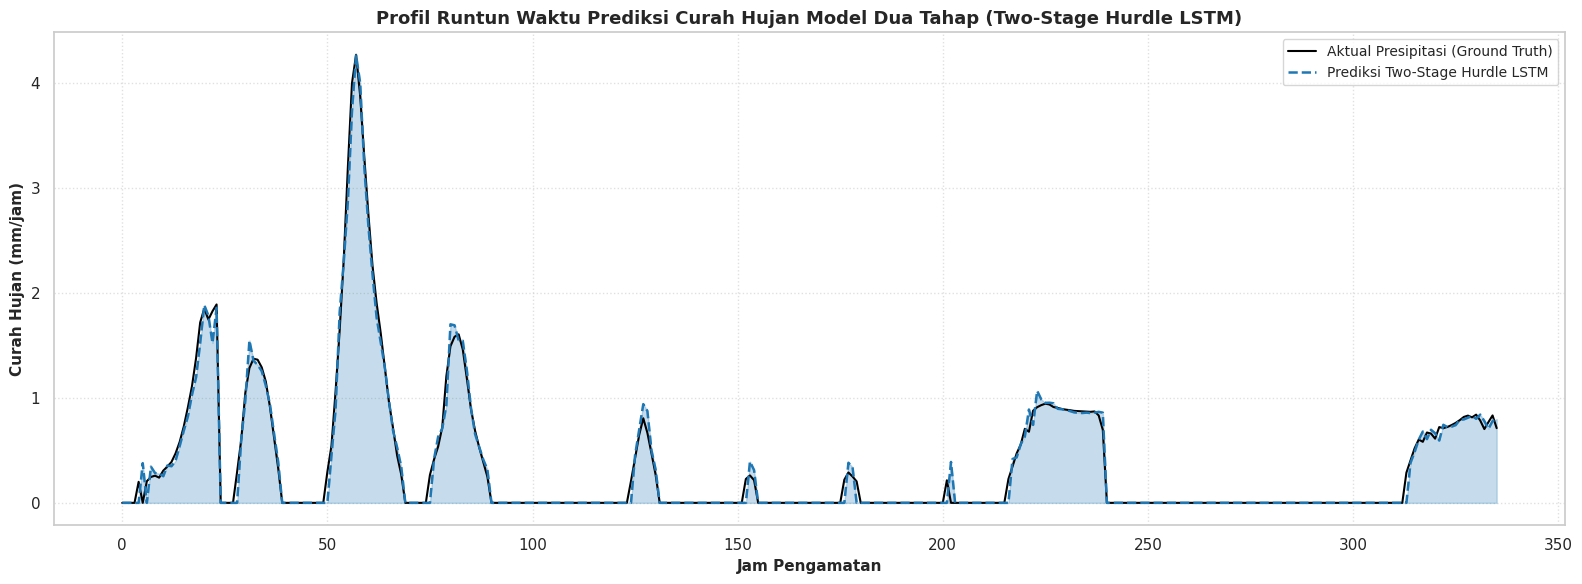

2026-10-30 06:27:22,557 - INFO - Menghasilkan rangkaian visualisasi evaluasi performa model dua tahap terpisah...


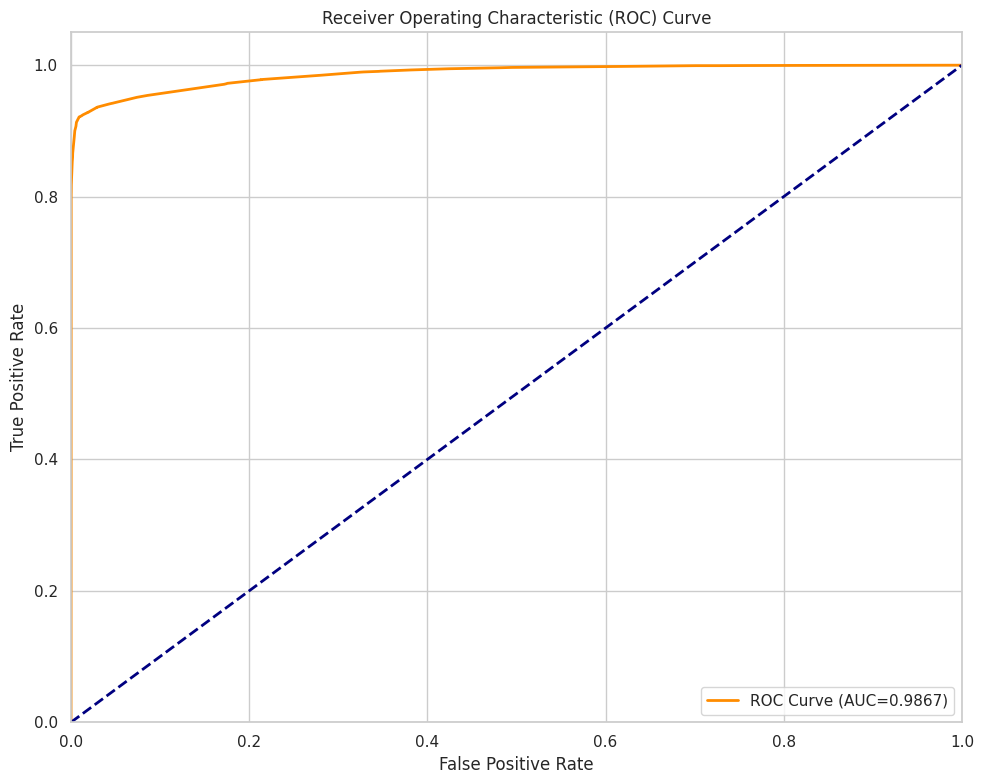

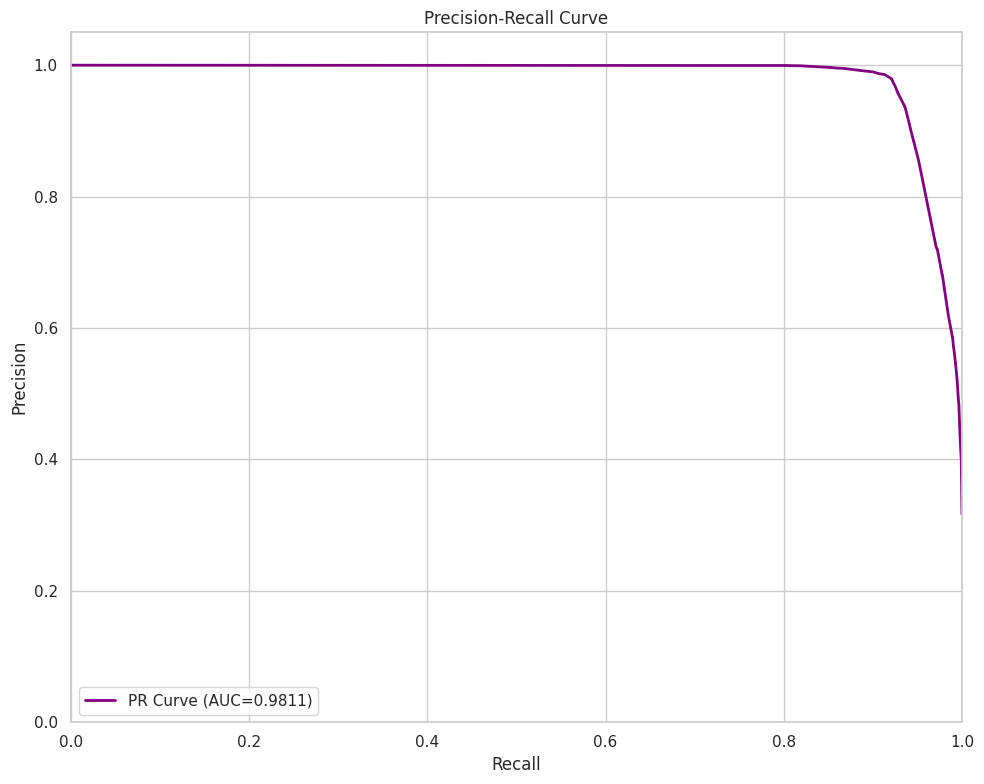

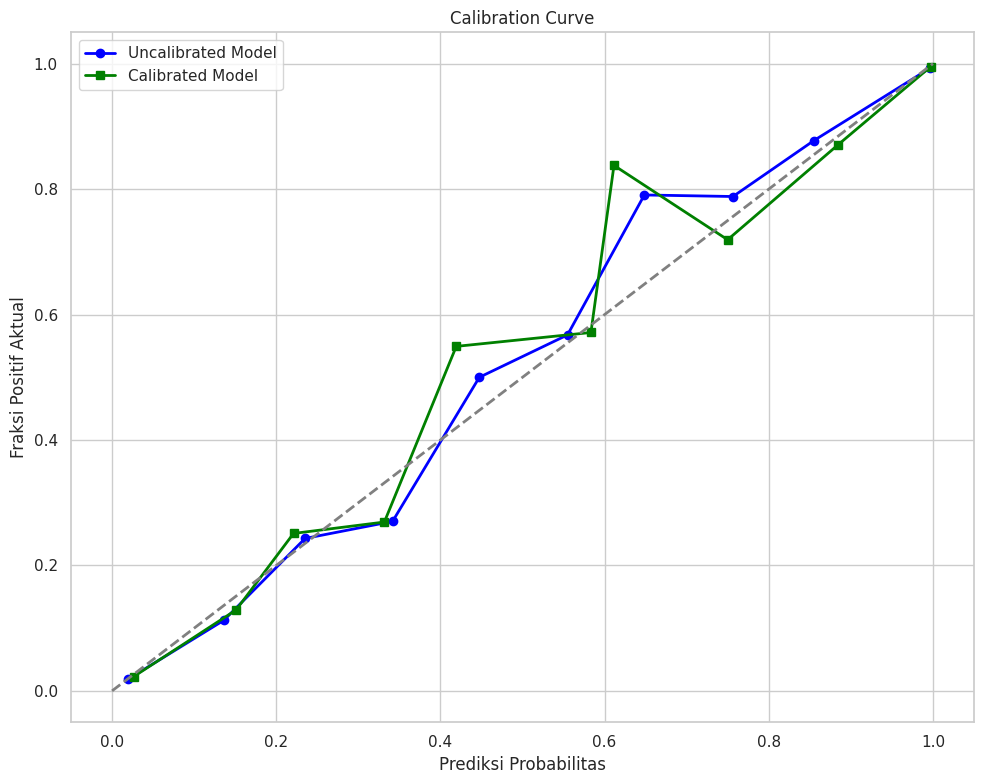

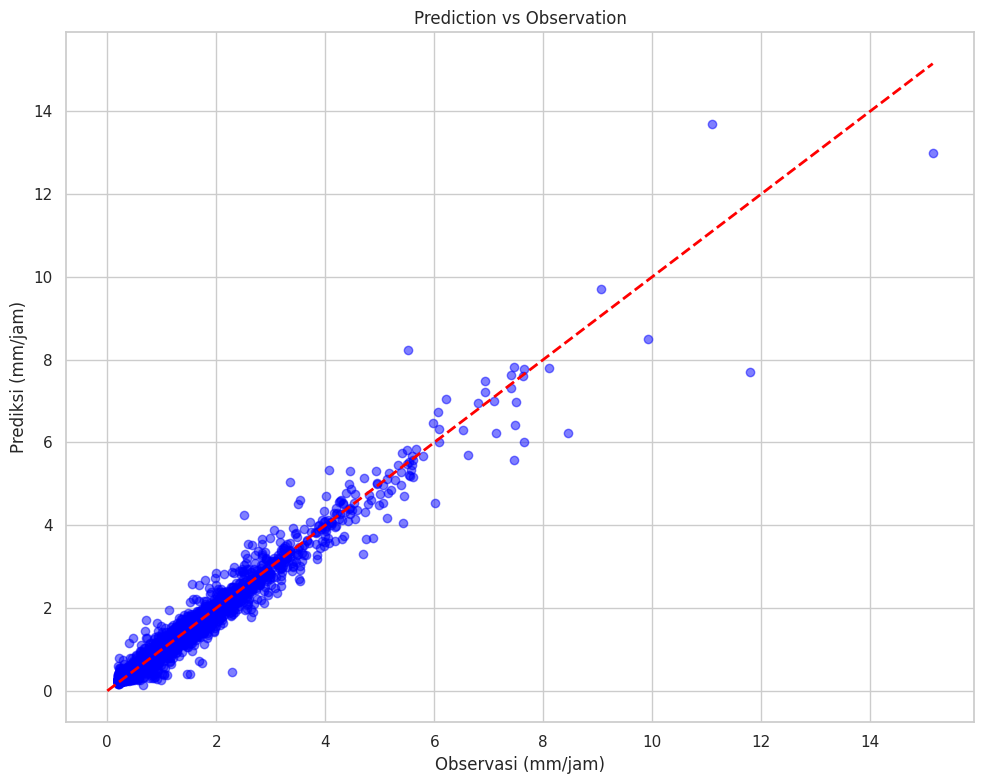

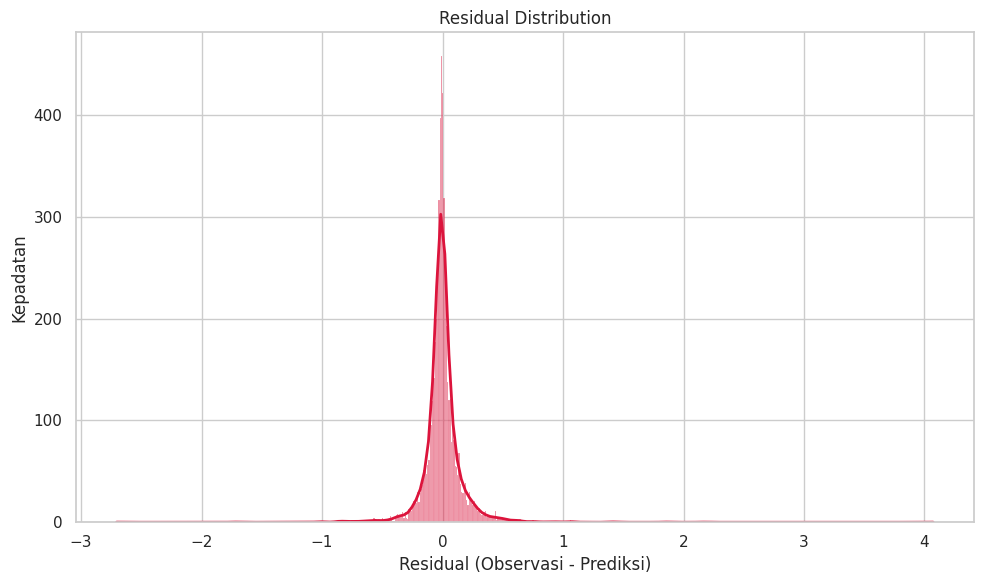

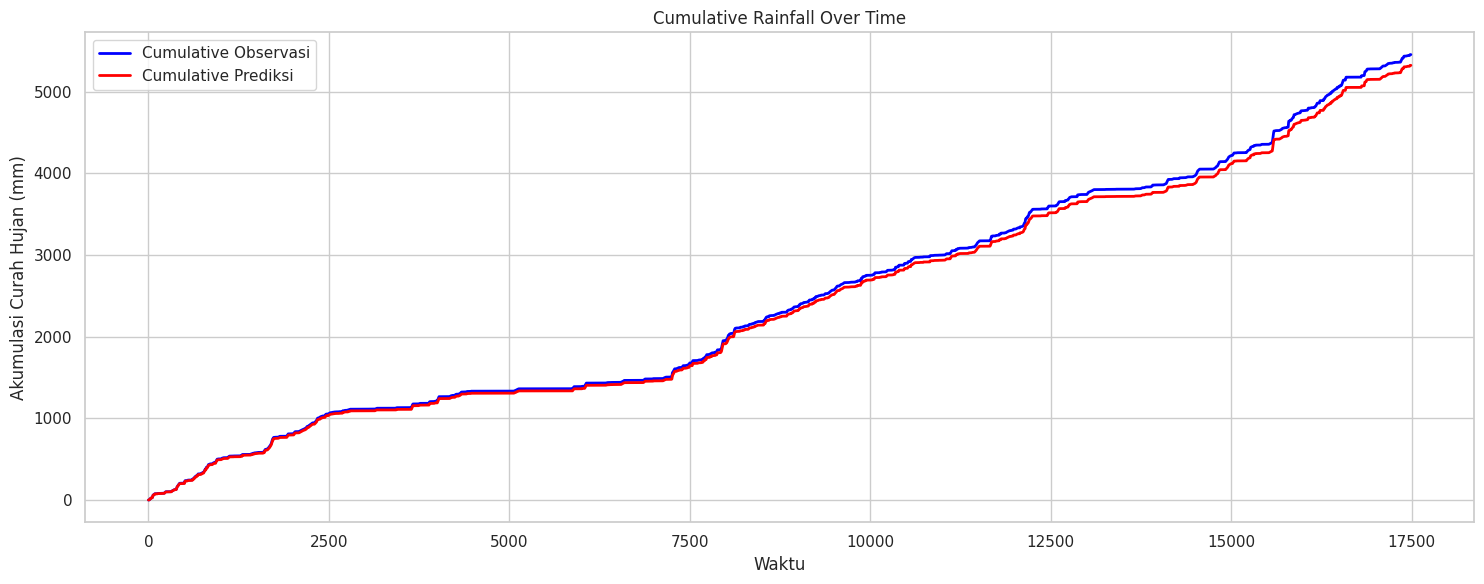

2026-10-30 06:27:27,717 - INFO - Evaluasi Komprehensif Model Two-Stage Hurdle Selesai!


In [13]:
# Sel 9: Evaluasi Terpadu Model Dua Tahap (Two-Stage Hurdle LSTM)
import numpy as np
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

logger.info("Memulai Evaluasi Terpadu Model Dua Tahap (Two-Stage Hurdle LSTM)...")
evaluator_final = ModelEvaluator(BASE_OUTPUT_DIR)

# 1. Pemuatan model terbaik hasil Bayesian Optimization
clf_best = tf.keras.models.load_model(evaluator_final.dirs['models_clf'] / 'best_lstm_occ.keras')
reg_best = tf.keras.models.load_model(evaluator_final.dirs['models_reg'] / 'best_lstm_reg.keras') if (evaluator_final.dirs['models_reg'] / 'best_lstm_reg.keras').exists() else None

# 2. Pemuatan kalibrator & ambang batas klasifikasi optimal
calibrator = joblib.load(evaluator_final.dirs['models_cal'] / 'isotonic_calibrator.pkl')
cal_meta = joblib.load(evaluator_final.dirs['models_cal'] / 'calibration_meta.pkl')
cal_method = cal_meta['method']

_thresh_file = evaluator_final.dirs['models_clf'] / 'best_threshold_pretrain.pkl'
best_threshold = joblib.load(_thresh_file) if _thresh_file.exists() else 0.5
logger.info(f"Threshold klasifikasi optimal: {best_threshold:.2f} (Metode Kalibrasi: {cal_method})")

# 3. Inferensi Tahap 1: Klasifikasi Kejadian Hujan
test_prob_uncal = clf_best.predict(X_te_seq, verbose=0).flatten()
test_prob_cal = apply_calibrator(calibrator, cal_method, test_prob_uncal)
test_preds_occ = (test_prob_cal >= best_threshold).astype(int)

# 4. Inferensi Tahap 2: Regresi Intensitas Dua Tahap (Hurdle)
test_preds_amount = np.zeros(len(y_te_o))
predicted_rainy_idx = np.where(test_preds_occ == 1)[0]
if reg_best is not None and len(predicted_rainy_idx) > 0:
    raw_reg_pred = reg_best.predict(X_te_seq[predicted_rainy_idx], verbose=0).flatten()
    test_preds_amount[predicted_rainy_idx] = np.clip(np.expm1(raw_reg_pred), 0, None)

# 5. Evaluasi Metrik Klasifikasi (Tahap 1)
clf_metrics, meteo_metrics = evaluator_final.evaluate_classification(
    y_te_o, test_prob_uncal, test_prob_cal, test_preds_occ
)
ece, mce = compute_ece_mce(y_te_o, test_prob_cal)
clf_metrics['ECE'] = ece
clf_metrics['MCE'] = mce
evaluator_final.save_combined_metrics()

# Visualisasi Matriks Konfusi
evaluator_final.plot_confusion_matrix(y_te_o, test_preds_occ, filename='20_confusion_matrix_two_stage.png', suffix='(Two-Stage Hurdle)')
evaluator_final.plot_confusion_matrix(y_te_o, test_preds_occ, filename='confusion_matrix_two_stage.png', suffix='(Two-Stage Hurdle)')

# 6. Evaluasi Metrik Regresi Kondisional (Khusus Sampel Hujan Aktual)
rainy_actual_idx = y_te_o == 1
if np.sum(rainy_actual_idx) > 0:
    reg_preds_on_rainy = np.clip(np.expm1(reg_best.predict(X_te_seq[rainy_actual_idx], verbose=0).flatten()), 0, None) if reg_best is not None else np.zeros(np.sum(rainy_actual_idx))
    reg_metrics = evaluator_final.evaluate_regression(y_te_r[rainy_actual_idx], reg_preds_on_rainy)
else:
    reg_metrics = {}

# 7. Evaluasi Hurdle End-to-End pada Seluruh Sampel
hurdle_rmse = np.sqrt(mean_squared_error(y_te_r, test_preds_amount))
hurdle_mae  = mean_absolute_error(y_te_r, test_preds_amount)
hurdle_r2   = r2_score(y_te_r, test_preds_amount)
logger.info(f"[Two-Stage End-to-End Hurdle] RMSE: {hurdle_rmse:.4f} mm, MAE: {hurdle_mae:.4f} mm, R2: {hurdle_r2:.4f}")

# 8. Visualisasi Runtun Waktu Prediksi Dua Tahap (Plot 21 - Timeseries Window 336 Jam)
plt.figure(figsize=(16, 6))
plot_window = min(336, len(y_te_r))
time_axis = np.arange(plot_window)
plt.plot(time_axis, y_te_r[:plot_window], label='Aktual Presipitasi (Ground Truth)', color='black', linewidth=1.5)
plt.plot(time_axis, test_preds_amount[:plot_window], label='Prediksi Two-Stage Hurdle LSTM', color='#1f77b4', linewidth=1.8, linestyle='--')
plt.fill_between(time_axis, 0, test_preds_amount[:plot_window], color='#1f77b4', alpha=0.25)
plt.title('Profil Runtun Waktu Prediksi Curah Hujan Model Dua Tahap (Two-Stage Hurdle LSTM)', fontsize=13, fontweight='bold')
plt.xlabel('Jam Pengamatan', fontsize=11, fontweight='bold')
plt.ylabel('Curah Hujan (mm/jam)', fontsize=11, fontweight='bold')
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
p21_path = evaluator_final.dirs['plots'] / '21_two_stage_timeseries_prediction.png'
plt.savefig(p21_path, dpi=300, bbox_inches='tight')
plt.savefig(evaluator_final.dirs['plots'] / 'two_stage_timeseries_prediction.png', dpi=300, bbox_inches='tight')
logger.info(f"Plot runtun waktu prediksi dua tahap disimpan: {p21_path}")
plt.show()
plt.close()

# 8.5. Rangkaian Plot Diagnostik Lengkap Model Dua Tahap (Plot 22 - 27)
logger.info("Menghasilkan rangkaian visualisasi evaluasi performa model dua tahap terpisah...")
evaluator_final.plot_roc_curve(y_te_o, test_prob_cal, filename='22_two_stage_roc_curve.png')
evaluator_final.plot_precision_recall_curve(y_te_o, test_prob_cal, filename='23_two_stage_precision_recall_curve.png')
evaluator_final.plot_calibration_curve(y_te_o, test_prob_uncal, test_prob_cal, filename='24_two_stage_calibration_curve.png')

if np.sum(rainy_actual_idx) > 0 and reg_best is not None:
    evaluator_final.plot_prediction_vs_observation(
        y_te_r[rainy_actual_idx], reg_preds_on_rainy, filename='25_two_stage_prediction_vs_observation.png'
    )
    residuals_rain = y_te_r[rainy_actual_idx] - reg_preds_on_rainy
    evaluator_final.plot_residual_distribution(
        residuals_rain, filename='26_two_stage_residual_distribution.png'
    )

evaluator_final.plot_cumulative_rainfall(
    y_te_r, test_preds_amount, timestamps=np.arange(len(y_te_r)), filename='27_two_stage_cumulative_rainfall.png'
)

# 9. Pembuatan Laporan Evaluasi Komprehensif
evaluator_final.generate_report(
    len(X_tr_seq), len(X_va_seq), len(X_te_seq),
    list(scaler.feature_names_in_),
    clf_metrics, meteo_metrics, reg_metrics,
    "Two-Stage Hurdle LSTM (Bayesian Optimization)"
)
logger.info("Evaluasi Komprehensif Model Two-Stage Hurdle Selesai!")


## Analisis SHAP (*Feature Importance* LSTM)

Menghasilkan visualisasi *GradientExplainer* (SHAP) untuk membongkar kotak hitam jaringan saraf tiruan. Grafik ini menunjukkan **variabel mana yang paling kuat pengaruhnya** dalam memicu prediksi hujan lebat.

2026-10-30 06:27:29,966 - INFO - Membangkitkan plot SHAP untuk Model LSTM...


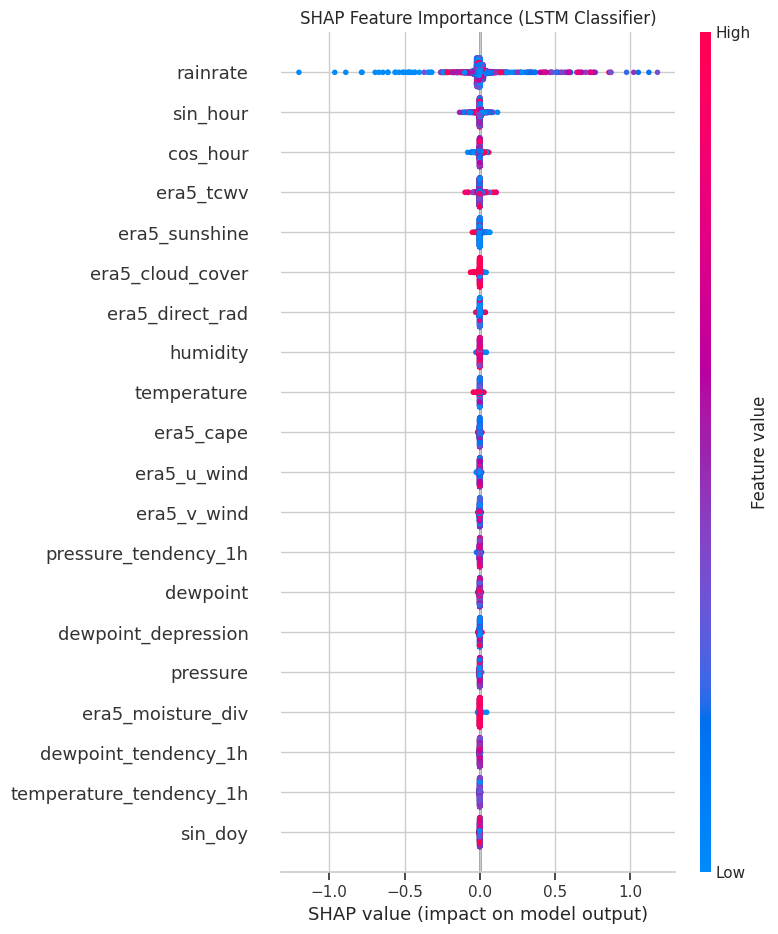

2026-10-30 06:27:36,047 - INFO - Plot SHAP berhasil disimpan!


In [14]:
# ======================================================
# Analisis SHAP (Feature Importance) - FIXED VERSION
# ======================================================
import shap
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

logger.info("Membangkitkan plot SHAP untuk Model LSTM...")

try:
    # Gunakan GradientExplainer (lebih stabil di TF2 keras)
    background = X_tr_seq[:100]
    explainer = shap.GradientExplainer(clf_best, background)
    
    # Hitung SHAP values untuk sampel test
    X_shap = X_te_seq[:100]
    shap_values = explainer.shap_values(X_shap)
    
    # --------------------------------------------------
    # FIX 1: Logika Ekstraksi & Penyelarasan Tipe Data
    # --------------------------------------------------
    # Ambil array dari list (biasanya SHAP mengembalikan list berisi 1 elemen per kelas)
    if isinstance(shap_values, list):
        shap_vals = shap_values[0]
    else:
        shap_vals = shap_values
        
    # Konversi EagerTensor ke NumPy Array jika diperlukan
    if hasattr(shap_vals, 'numpy'):
        shap_vals = shap_vals.numpy()
    if hasattr(X_shap, 'numpy'):
        X_shap_np = X_shap.numpy()
    else:
        X_shap_np = X_shap
        
    # --------------------------------------------------
    # FIX 2: Squeeze Dimensi Ekstra Secara Aman
    # --------------------------------------------------
    # Keras TF2/3 kadang mengembalikan tensor 4D seperti (samples, time, features, 1)
    if len(shap_vals.shape) == 4:
        if shap_vals.shape[-1] == 1:
            shap_vals = shap_vals.squeeze(-1)
        elif shap_vals.shape[0] == 1:
            shap_vals = shap_vals.squeeze(0)

    # --------------------------------------------------
    # FIX 3: Flatten Dimensi Wاقات (3D ke 2D)
    # --------------------------------------------------
    # Menggabungkan dimensi waktu: dari (samples, timesteps, features) menjadi (samples * timesteps, features)
    shap_values_2d = shap_vals.reshape(-1, shap_vals.shape[-1])
    X_shap_2d = X_shap_np.reshape(-1, X_shap_np.shape[-1])
    
    # --------------------------------------------------
    # Visualisasi Summary Plot
    # --------------------------------------------------
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values_2d, X_shap_2d, feature_names=X.columns, show=False)
    plt.title('SHAP Feature Importance (LSTM Classifier)')
    plt.tight_layout()
    plt.savefig(evaluator.dirs['plots'] / '28_shap_feature_importance.png', dpi=300, bbox_inches='tight')
    plt.savefig(evaluator.dirs['plots'] / 'shap_summary_clf.png', dpi=300, bbox_inches='tight')
    plt.show()
    logger.info("Plot SHAP berhasil disimpan!")

except Exception as e:
    logger.error(f"SHAP Explainer gagal pada LSTM: {e}")
